# Peloton Subscription Churn Analysis
## Exploratory Data Analysis & Business Insights

**Author:** Naveen Kumar K | **Dataset:** Peloton Subscription & Usage Data  
**Analysis Date:** 2025 | **Tools:** Python · SQL · Pandas · Seaborn · SciPy

---

## 1. Executive Summary

This project analyses 4,200 Peloton subscribers across 18 months of subscription and usage data to identify the strongest evidence-based drivers of subscription churn and translate those findings into actionable retention recommendations.

**Overall churn rate:** 42.1% of customers cancelled their subscription within the observation window (Jul 2024 – Dec 2025).

**Three most important findings:**

> **Finding 1 — Low Engagement is the strongest behavioural predictor of churn.**  
> Churned subscribers completed a median of 2.0 workouts per month vs 4.1 for retained subscribers (rank-biserial r = −0.37, p < 0.001). This gap is consistent across all tenure bands and is corroborated by the most common stated cancellation reason ("not using enough", 41% of known reasons).

> **Finding 2 — Monthly-plan subscribers churn at nearly twice the rate of annual-plan subscribers** (51.2% vs 26.4%), and this difference persists within every tenure band after controlling for right-censoring. The structural commitment difference between billing cycles is a primary churn driver — not merely a reflection of tenure distribution.

> **Finding 3 — Promo-offer subscribers churn at a materially higher rate** (50.8% vs 39.6% for all other channels combined). This gap persists within plan types: promo monthly subscribers churn at 63.3% vs 47.7% for non-promo monthly. This suggests promo-acquired customers have weaker intrinsic motivation and require dedicated early-engagement interventions.

**Key recommendation:** Invest in first-30-day activation. Churned subscribers showed lower first-month engagement (median 2.0 vs 4.0 workouts) and were twice as likely to complete zero workouts in their first month (12.9% vs 6.5%). Improving early habit formation is the highest-leverage retention action available.


---
## 2. Business Problem

Peloton's fitness app offers on-demand workouts and live classes via monthly and annual subscriptions. Subscription cancellations are increasing, and leadership wants to understand why subscribers are leaving and what actions can improve retention.

**Central business question:**
> What customer characteristics, subscription attributes, engagement patterns, and behavioural factors are associated with subscription churn — and what evidence-based actions should Peloton prioritise to improve retention?

This project is an **EDA and business analysis project**. It identifies associations, not causal relationships. No machine learning models are built.


---
## 3. Analytical Objectives

Following the DCS project specification, this analysis must:

1. Load and clean both datasets; document all data-quality issues
2. Define churn and tenure defensibly
3. Account for right-censoring — newer subscribers have had less time to cancel
4. Explore churn across plan type, tier, acquisition channel, device, age group, and tenure
5. Analyse engagement, support contacts, and their relationship with churn
6. Specifically examine first-month customer behaviour
7. Identify the **Top 3 factors associated with churn**
8. Validate those factors after controlling for tenure
9. Compare behavioural evidence with stated cancellation reasons
10. Produce a concise, evidence-backed recommendation with specific actions and success metrics


---
## 4. Dataset Overview

Two CSV files are provided:

| File | Rows | Columns | Grain |
|---|---|---|---|
| `subscriptions.csv` | 4,200 | 11 | One row per customer |
| `usage.csv` | 30,685 (raw) | 6 | One row per customer per month |

### Data Dictionary

**subscriptions.csv**

| Column | Type | Description |
|---|---|---|
| `customer_id` | int | Unique customer identifier (primary key) |
| `signup_date` | date | Date the customer subscribed |
| `plan_type` | str | Billing cycle: `monthly` or `annual` |
| `plan_tier` | str | Feature tier: `basic`, `plus`, `premium` (had capitalisation inconsistency) |
| `monthly_price` | float | Monthly billing amount (6 fixed price points) |
| `acquisition_channel` | str | How acquired: `organic`, `paid_social`, `promo_offer`, `referral`, `partner` |
| `primary_device` | str | Platform: `ios`, `android`, `web` |
| `age_group` | str | Age bracket: `18-24`, `25-34`, `35-44`, `45-54`, `55+` |
| `churned` | str | Whether the customer cancelled: `yes` / `no` |
| `churn_date` | date/null | Date of cancellation (null for active customers) |
| `cancel_reason` | str/null | Stated cancellation reason (available for 78.4% of churners) |

**usage.csv**

| Column | Type | Description |
|---|---|---|
| `customer_id` | int | Foreign key → subscriptions.csv |
| `month` | str | Usage month in YYYY-MM format |
| `workouts_completed` | int | Workouts completed in that month (0–48) |
| `minutes_active` | float | Active minutes (0–1,653; 506 null values) |
| `classes_booked` | int | Classes booked (0–16) |
| `support_tickets` | int | Support contacts raised (0–4) |

**Dataset relationship:** All 4,200 `customer_id` values are present in both tables. No orphan records in either direction.


---
## 5. Data Quality Assessment


In [ ]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Load raw data
subs_raw  = pd.read_csv('../data/subscriptions.csv')
usage_raw = pd.read_csv('../data/usage.csv')

print("=" * 60)
print("RAW DATA SHAPES")
print("=" * 60)
print(f"subscriptions.csv : {subs_raw.shape[0]:,} rows × {subs_raw.shape[1]} columns")
print(f"usage.csv         : {usage_raw.shape[0]:,} rows × {usage_raw.shape[1]} columns")

print("\n" + "=" * 60)
print("COMPLETENESS — MISSING VALUES")
print("=" * 60)
print("subscriptions.csv:")
print(subs_raw.isnull().sum().to_string())
print("\nusage.csv:")
print(usage_raw.isnull().sum().to_string())

print("\n" + "=" * 60)
print("UNIQUENESS — DUPLICATE RECORDS")
print("=" * 60)
print(f"Duplicate customer_id in subscriptions : {subs_raw['customer_id'].duplicated().sum()}")
usage_raw['month_dt'] = pd.to_datetime(usage_raw['month'])
print(f"Duplicate (customer_id, month) in usage: {usage_raw.duplicated(subset=['customer_id','month']).sum()}")

print("\n" + "=" * 60)
print("CONSISTENCY — plan_tier capitalisation")
print("=" * 60)
print(subs_raw['plan_tier'].value_counts().to_string())

print("\n" + "=" * 60)
print("VALIDITY — LOGICAL CHECKS")
print("=" * 60)
subs_raw['signup_date'] = pd.to_datetime(subs_raw['signup_date'])
subs_raw['churn_date']  = pd.to_datetime(subs_raw['churn_date'], errors='coerce')
print(f"Churn date BEFORE signup date     : {(subs_raw['churn_date'] < subs_raw['signup_date']).sum()}")
print(f"churned=yes with no churn_date    : {((subs_raw['churned']=='yes') & subs_raw['churn_date'].isna()).sum()}")
print(f"churned=no  with churn_date       : {((subs_raw['churned']=='no') & subs_raw['churn_date'].notna()).sum()}")
print(f"Negative workouts in usage        : {(usage_raw['workouts_completed'] < 0).sum()}")
print(f"Negative minutes in usage         : {(usage_raw['minutes_active'] < 0).sum()}")
usage_raw_clean = usage_raw.drop_duplicates(subset=['customer_id','month'])
merged_check = usage_raw_clean.merge(subs_raw[['customer_id','signup_date','churn_date','churned']], on='customer_id')
merged_check['churn_m'] = merged_check['churn_date'].dt.to_period('M').dt.to_timestamp()
late_rows = merged_check[(merged_check['churned']=='yes') & (merged_check['month_dt'] > merged_check['churn_m'])]
print(f"Usage rows after churn month      : {len(late_rows)}")

print("\n" + "=" * 60)
print("REFERENTIAL INTEGRITY")
print("=" * 60)
usage_ids = set(usage_raw['customer_id'].unique())
subs_ids  = set(subs_raw['customer_id'].unique())
print(f"IDs in usage NOT in subscriptions : {len(usage_ids - subs_ids)}")
print(f"IDs in subscriptions NOT in usage : {len(subs_ids - usage_ids)}")

print("\n" + "=" * 60)
print("CANCEL REASON COVERAGE")
print("=" * 60)
churned = subs_raw[subs_raw['churned']=='yes']
print(f"Total churned: {len(churned)}")
print(f"With cancel reason  : {churned['cancel_reason'].notna().sum()} ({churned['cancel_reason'].notna().mean():.1%})")
print(f"Missing cancel reason: {churned['cancel_reason'].isna().sum()} ({churned['cancel_reason'].isna().mean():.1%})")


RAW DATA SHAPES
subscriptions.csv : 4,200 rows × 11 columns
usage.csv         : 30,685 rows × 6 columns

COMPLETENESS — MISSING VALUES
subscriptions.csv:
customer_id               0
signup_date               0
plan_type                 0
plan_tier                 0
monthly_price             0
acquisition_channel       0
primary_device            0
age_group                 0
churned                   0
churn_date             2432
cancel_reason          2814

usage.csv:
customer_id             0
month                   0
workouts_completed      0
minutes_active        506
classes_booked          0
support_tickets         0

UNIQUENESS — DUPLICATE RECORDS
Duplicate customer_id in subscriptions : 0
Duplicate (customer_id, month) in usage: 160

CONSISTENCY — plan_tier capitalisation
plan_tier
basic      1929
plus       1462
premium     708
Basic        47
Plus         39
Premium      15

VALIDITY — LOGICAL CHECKS
Churn date BEFORE signup date     : 0
churned=yes with no churn_date    : 0
c

### Data Quality Summary

| Issue | Detail | Resolution |
|---|---|---|
| `plan_tier` capitalisation | 101 rows with Title Case (`Basic`, `Plus`, `Premium`) | Normalise to lowercase — `str.lower()` |
| Duplicate usage rows | 160 exact duplicate `(customer_id, month)` pairs | Drop one copy of each — data export artifact |
| `cancel_reason` nulls (active) | 2,432 active customers have no reason (expected) | Recode as `'not_applicable'` |
| `cancel_reason` nulls (churned) | 382 churned customers missing reason (21.6%) | Recode as `'unknown'`; note in analysis |
| `minutes_active` nulls | 506 rows (1.65%); appears random (MCAR) | Exclude rows from minutes-specific analyses; do not impute |
| Zero-tenure customers | 7 customers where `churn_date == signup_date` | Retain; flag as same-day cancellations |

No data was fabricated or imputed. Every cleaning decision is documented and reproducible.


---
## 6. Data Preparation

Six analytical tables are built from the cleaned data. Each has a defined grain, purpose, and explicit leakage-prevention rule.


In [ ]:
# ── GLOBAL CONSTANTS ─────────────────────────────────────
CUTOFF     = pd.Timestamp('2025-12-31')   # Analysis observation end date
BAND_ORDER = ['0–1 month', '2–3 months', '4–6 months', '7–12 months', '13+ months']
DATA_PATH  = '../data/'

# ── LOAD ─────────────────────────────────────────────────
subs_raw  = pd.read_csv(f'{DATA_PATH}subscriptions.csv')
usage_raw = pd.read_csv(f'{DATA_PATH}usage.csv')

# ════════════════════════════════════════════════════════
# TABLE 1 — customer_base
# Grain: one row per customer
# ════════════════════════════════════════════════════════
cb = subs_raw.copy()
cb['signup_date'] = pd.to_datetime(cb['signup_date'])
cb['churn_date']  = pd.to_datetime(cb['churn_date'], errors='coerce')
cb['plan_tier']   = cb['plan_tier'].str.lower().str.strip()
cb['churned_flag']= (cb['churned'] == 'yes').astype(int)

# Recode cancel_reason nulls
cb['cancel_reason'] = np.select(
    [cb['churned']=='no', (cb['churned']=='yes') & cb['cancel_reason'].isna()],
    ['not_applicable', 'unknown'],
    default=cb['cancel_reason']
)

# Tenure (30-day approximation; documented assumption)
cb['observation_end_date'] = pd.to_datetime(
    np.where(cb['churned']=='yes', cb['churn_date'], CUTOFF)
)
cb['tenure_days']   = (cb['observation_end_date'] - cb['signup_date']).dt.days
cb['tenure_months'] = cb['tenure_days'] // 30   # completed 30-day months

def assign_tenure_band(m):
    if m <= 1:    return '0–1 month'
    elif m <= 3:  return '2–3 months'
    elif m <= 6:  return '4–6 months'
    elif m <= 12: return '7–12 months'
    else:         return '13+ months'

cb['tenure_band'] = pd.Categorical(
    cb['tenure_months'].apply(assign_tenure_band),
    categories=BAND_ORDER, ordered=True
)
cb['zero_tenure']    = cb['tenure_days'] == 0
cb['signup_period']  = cb['signup_date'].dt.to_period('M')

print(f"customer_base: {cb.shape[0]:,} rows × {cb.shape[1]} columns")
print(f"  Churned: {cb['churned_flag'].sum():,} ({cb['churned_flag'].mean():.1%})")
print(f"  Active:  {(1-cb['churned_flag']).sum():,} ({(1-cb['churned_flag']).mean():.1%})")
print(f"  Tenure range (30-day approx): {cb['tenure_months'].min()}–{cb['tenure_months'].max()} months")
print(f"  Zero-tenure customers: {cb['zero_tenure'].sum()}")

# ════════════════════════════════════════════════════════
# TABLE 2 — usage_clean
# Grain: one row per customer-month (deduplicated)
# ════════════════════════════════════════════════════════
usage = usage_raw.copy()
usage['month_dt']     = pd.to_datetime(usage['month'])
usage['month_period'] = usage['month_dt'].dt.to_period('M')
n_raw = len(usage)
usage = usage.drop_duplicates(subset=['customer_id', 'month'])
print(f"\nusage_clean: {n_raw:,} → {len(usage):,} rows (removed {n_raw - len(usage)} exact duplicates)")

# ════════════════════════════════════════════════════════
# TABLE 3 — customer_usage_summary
# Grain: one row per customer; per-month averages
# ════════════════════════════════════════════════════════
usage_j = usage.merge(
    cb[['customer_id','churn_date','churned']], on='customer_id', how='left'
)
# Defensive post-churn exclusion filter
usage_j['churn_ms'] = usage_j['churn_date'].dt.to_period('M').dt.to_timestamp()
mask_post = (usage_j['churned']=='yes') & (usage_j['month_dt'] > usage_j['churn_ms'])
usage_v   = usage_j[~mask_post].copy()
print(f"\nPost-churn rows excluded by defensive filter: {mask_post.sum()}")

cus = usage_v.groupby('customer_id').agg(
    avg_monthly_workouts  = ('workouts_completed', 'mean'),
    avg_monthly_minutes   = ('minutes_active',     'mean'),   # NaN rows auto-excluded from mean
    avg_monthly_classes   = ('classes_booked',     'mean'),
    avg_monthly_support   = ('support_tickets',    'mean'),
    total_support_tickets = ('support_tickets',    'sum'),
    months_in_usage       = ('month_dt',           'count')
).reset_index()
cus['any_support_contact'] = (cus['total_support_tickets'] > 0).astype(int)
cus = cus.merge(cb[['customer_id','churned_flag','tenure_months','tenure_band']], on='customer_id')
print(f"customer_usage_summary: {cus.shape[0]:,} rows × {cus.shape[1]} columns")

# ════════════════════════════════════════════════════════
# TABLE 4 — first_month_usage
# Grain: one row per customer; first subscription month only
# ════════════════════════════════════════════════════════
fm = usage.merge(
    cb[['customer_id','signup_period','churned_flag','churn_date']], on='customer_id'
)
fm = fm[fm['month_period'] == fm['signup_period']].copy()
fm['first_month_churner'] = (
    (fm['churned_flag'] == 1) &
    fm['churn_date'].notna() &
    (pd.to_datetime(fm['churn_date']).dt.to_period('M') == fm['signup_period'])
)
fm_all = cb[['customer_id','signup_period','churned_flag']].merge(
    fm[['customer_id','workouts_completed','minutes_active',
        'classes_booked','support_tickets','first_month_churner']],
    on='customer_id', how='left'
)
fm_all.columns = ['customer_id','signup_period','churned_flag',
                  'fm_workouts','fm_minutes','fm_classes','fm_support','first_month_churner']
fm_all['missing_first_month'] = fm_all['fm_workouts'].isna()
print(f"first_month_usage: {fm_all.shape[0]:,} rows; missing first-month records: {fm_all['missing_first_month'].sum()}")
print(f"  First-month churners: {fm_all['first_month_churner'].sum()}")

# ════════════════════════════════════════════════════════
# TABLE 5 — pre_churn_behavior
# Grain: one row per customer; 3-month pre-index averages
# Index month = churn_month for churned; 2025-12 for active
# ════════════════════════════════════════════════════════
cb['index_month'] = cb['churn_date'].dt.to_period('M')
cb.loc[cb['churned']=='no', 'index_month'] = pd.Period('2025-12', freq='M')

# Vectorised: build per-customer target month sets and merge
all_pre = []
for cid, grp in usage.groupby('customer_id'):
    idx_p  = cb.loc[cb['customer_id']==cid, 'index_month'].values[0]
    target = {idx_p - i for i in range(1, 4)}
    sub    = grp[grp['month_period'].isin(target)]
    n_av   = len(sub)
    all_pre.append({
        'customer_id':          cid,
        'pre_avg_workouts':     sub['workouts_completed'].mean() if n_av > 0 else np.nan,
        'pre_avg_minutes':      sub['minutes_active'].mean()     if n_av > 0 else np.nan,
        'pre_avg_classes':      sub['classes_booked'].mean()     if n_av > 0 else np.nan,
        'pre_avg_support':      sub['support_tickets'].mean()    if n_av > 0 else np.nan,
        'months_available_pre': n_av
    })
pre_churn = pd.DataFrame(all_pre)
pre_churn = pre_churn.merge(cb[['customer_id','churned_flag']], on='customer_id')
print(f"pre_churn_behavior: {pre_churn.shape[0]:,} rows")
print(f"  Customers with 0 pre-index months: {(pre_churn['months_available_pre']==0).sum()}")
print(f"  Customers with full 3 months     : {(pre_churn['months_available_pre']==3).sum()}")

# ════════════════════════════════════════════════════════
# TABLE 6 — monthly_churn_metrics
# Grain: one row per calendar month
# ════════════════════════════════════════════════════════
months = pd.period_range('2024-07','2025-12', freq='M')
mchurn_rows = []
for m in months:
    m_start = m.to_timestamp()
    m_end   = (m + 1).to_timestamp()
    churns   = subs_raw[
        (pd.to_datetime(subs_raw['churn_date']) >= m_start) &
        (pd.to_datetime(subs_raw['churn_date']) <  m_end)
    ].shape[0]
    active_start = subs_raw[
        (pd.to_datetime(subs_raw['signup_date']) < m_start) &
        (subs_raw['churn_date'].isna() | (pd.to_datetime(subs_raw['churn_date']) >= m_start))
    ].shape[0]
    mchurn_rows.append({
        'month': str(m), 'month_dt': m_start,
        'churns': churns, 'active_start': active_start,
        'monthly_churn_rate': churns / active_start if active_start > 0 else np.nan
    })
mchurn = pd.DataFrame(mchurn_rows)
# Exclude Jul 2024 (no eligible denominator — first month of data)
mchurn = mchurn[mchurn['active_start'] > 0].copy()
print(f"\nmonthly_churn_metrics: {len(mchurn)} months (Aug 2024 – Dec 2025)")
print(f"  Mean monthly churn rate: {mchurn['monthly_churn_rate'].mean():.2%}")

print("\n✓ All 6 analytical tables built successfully")


customer_base: 4,200 rows × 18 columns
  Churned: 1,768 (42.1%)
  Active:  2,432 (57.9%)
  Tenure range (30-day approx): 0–18 months
  Zero-tenure customers: 7

usage_clean: 30,685 → 30,525 rows (removed 160 exact duplicates)

Post-churn rows excluded by defensive filter: 0
customer_usage_summary: 4,200 rows × 11 columns
first_month_usage: 4,200 rows; missing first-month records: 0
  First-month churners: 151


pre_churn_behavior: 4,200 rows
  Customers with 0 pre-index months: 273
  Customers with full 3 months     : 3156

monthly_churn_metrics: 17 months (Aug 2024 – Dec 2025)
  Mean monthly churn rate: 6.72%

✓ All 6 analytical tables built successfully


---
## 7. Customer Churn Overview

### 7.1 Churn Definition

A customer is **churned** if `churned == 'yes'` with a recorded `churn_date`.  
A customer is **active** (right-censored) if `churned == 'no'` — their observation ends at the analysis cutoff: **2025-12-31**.

**Two churn metrics are used:**
- **Cumulative churn rate:** churned customers / total customers — useful for overall context, but conflates customers with different exposure durations.
- **Monthly churn rate:** cancellations in month M / customers active at start of month M — the DCS-endorsed tenure-aware measure.

### 7.2 Right-Censoring Caveat

The 2,432 active customers are *not* a successfully retained group — they are right-censored observations. Customers who joined in mid-2025 have had only a few months of exposure. An unknown share will churn in 2026. The analysis does not describe active customers as "retained"; it treats them as censored until the observation cutoff.


OVERALL CHURN SUMMARY
Total customers  : 4,200
Churned          : 1,768  (42.1%)
Active (censored): 2,432  (57.9%)

Monthly churn rate stats:
  Mean  : 6.72%
  Min   : 5.30%  (2025-05)
  Max   : 11.01%  (2024-09)


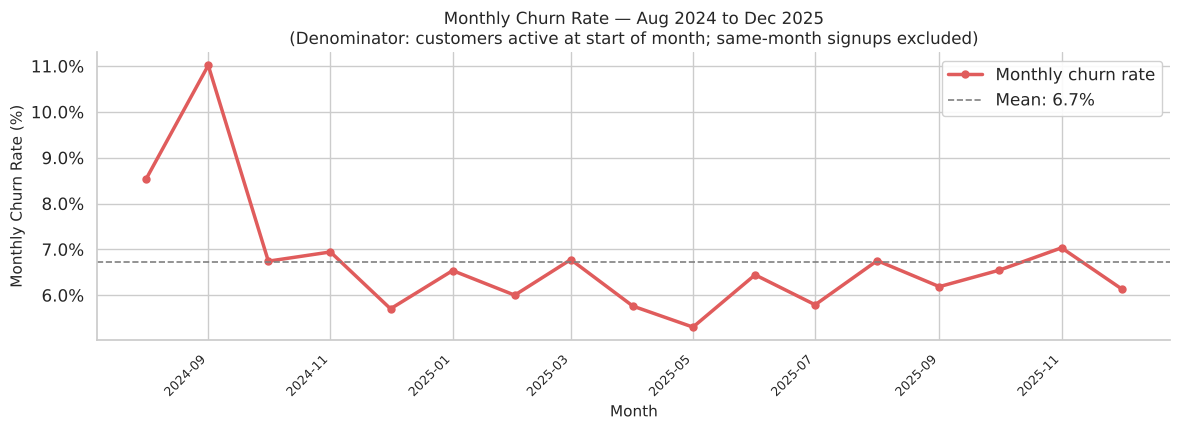

Chart 1: Monthly churn rate is relatively stable — 5–11% per month. Early months show higher volatility due to small active bases.


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ── Style setup ───────────────────────────────────────────
PALETTE = {'churned': '#E05C5C', 'active': '#5B8DB8', 'accent': '#F5A623'}
sns.set_style('whitegrid')
sns.set_context('notebook', font_scale=1.1)
plt.rcParams.update({'font.family':'DejaVu Sans', 'axes.spines.top':False, 'axes.spines.right':False})

# ── Overall churn ─────────────────────────────────────────
n_total   = len(cb)
n_churned = cb['churned_flag'].sum()
n_active  = n_total - n_churned

print("=" * 50)
print("OVERALL CHURN SUMMARY")
print("=" * 50)
print(f"Total customers  : {n_total:,}")
print(f"Churned          : {n_churned:,}  ({n_churned/n_total:.1%})")
print(f"Active (censored): {n_active:,}  ({n_active/n_total:.1%})")
print(f"\nMonthly churn rate stats:")
print(f"  Mean  : {mchurn['monthly_churn_rate'].mean():.2%}")
print(f"  Min   : {mchurn['monthly_churn_rate'].min():.2%}  ({mchurn.loc[mchurn['monthly_churn_rate'].idxmin(),'month']})")
print(f"  Max   : {mchurn['monthly_churn_rate'].max():.2%}  ({mchurn.loc[mchurn['monthly_churn_rate'].idxmax(),'month']})")

# ── CHART 1 — Monthly churn rate trend ───────────────────
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(mchurn['month_dt'], mchurn['monthly_churn_rate']*100,
        color=PALETTE['churned'], linewidth=2.5, marker='o', markersize=5, label='Monthly churn rate')
ax.axhline(mchurn['monthly_churn_rate'].mean()*100, color='grey', linestyle='--', linewidth=1.2, label=f"Mean: {mchurn['monthly_churn_rate'].mean():.1%}")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.set_xlabel('Month', fontsize=11)
ax.set_ylabel('Monthly Churn Rate (%)', fontsize=11)
ax.set_title('Monthly Churn Rate — Aug 2024 to Dec 2025\n(Denominator: customers active at start of month; same-month signups excluded)', fontsize=12)
ax.legend(framealpha=0.9)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.savefig('../reports/chart01_monthly_churn_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart 1: Monthly churn rate is relatively stable — 5–11% per month. Early months show higher volatility due to small active bases.")


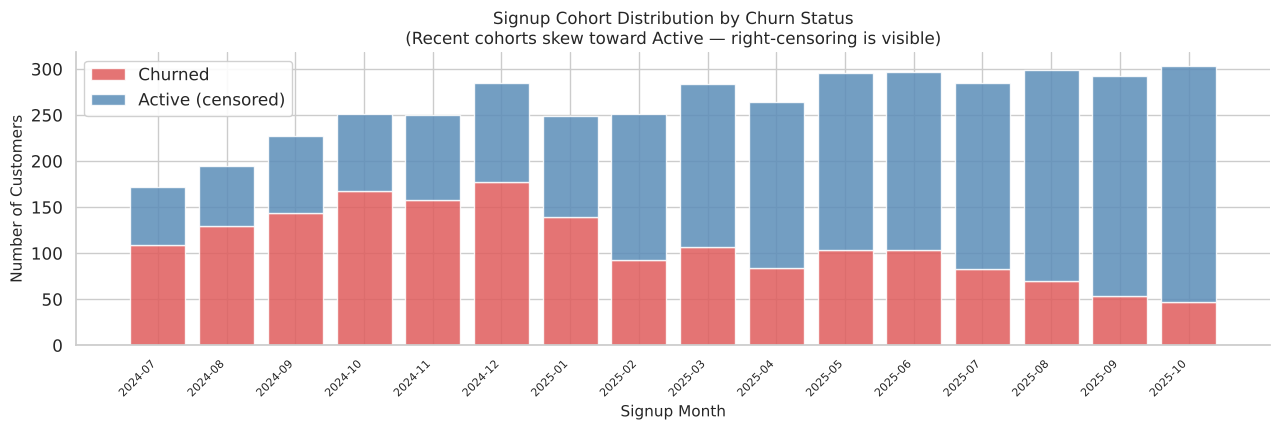

Chart 2: Recent cohorts (2025-Q3/Q4) are predominantly still active — not because they are loyal, but because they have had less time to churn. This illustrates the right-censoring risk in naive churn comparisons.


In [ ]:
# ── CHART 2 — Signup cohort distribution ─────────────────
cb['signup_month'] = cb['signup_date'].dt.to_period('M')
cohort = cb.groupby(['signup_month','churned_flag']).size().reset_index(name='count')
cohort['label'] = cohort['churned_flag'].map({0:'Active (censored)', 1:'Churned'})

fig, ax = plt.subplots(figsize=(13, 4.5))
months_ordered = sorted(cohort['signup_month'].unique())
bottom = {str(m): 0 for m in months_ordered}

colors = {1: PALETTE['churned'], 0: PALETTE['active']}
for flag in [1, 0]:
    sub = cohort[cohort['churned_flag']==flag]
    sub = sub.set_index('signup_month')
    xs  = [sub.loc[m,'count'] if m in sub.index else 0 for m in months_ordered]
    bots= [bottom[str(m)] for m in months_ordered]
    bars= ax.bar([str(m) for m in months_ordered], xs, bottom=bots,
                  color=colors[flag], label=sub['label'].values[0] if len(sub)>0 else '', alpha=0.85)
    for m, x in zip(months_ordered, xs):
        bottom[str(m)] += x

ax.set_xlabel('Signup Month', fontsize=11)
ax.set_ylabel('Number of Customers', fontsize=11)
ax.set_title('Signup Cohort Distribution by Churn Status\n(Recent cohorts skew toward Active — right-censoring is visible)', fontsize=12)
ax.legend(loc='upper left', framealpha=0.9)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.savefig('../reports/chart02_cohort_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart 2: Recent cohorts (2025-Q3/Q4) are predominantly still active — not because they are loyal, but because they have had less time to churn. This illustrates the right-censoring risk in naive churn comparisons.")


---
## 8. Tenure Analysis

**Tenure** measures how long a customer has been (or was) subscribed.

**Calculation:**  
- Churned customers: `tenure_months = (churn_date − signup_date).days // 30`  
- Active customers: `tenure_months = (2025-12-31 − signup_date).days // 30`  

The `// 30` formula is a **30-day approximation of completed billing months** — it is not an exact calendar-month count. This is documented throughout. For example, a customer who cancelled on day 59 has completed 1 full 30-day period and is assigned `tenure_months = 1`.

**Why tenure is central to this analysis:**  
If we simply compare "churned vs active" on any metric without controlling for tenure, we risk attributing churn to characteristics that are merely correlated with cohort age. Longer-tenured customers have had more time to either churn or demonstrate loyalty. All major findings are validated within tenure bands.


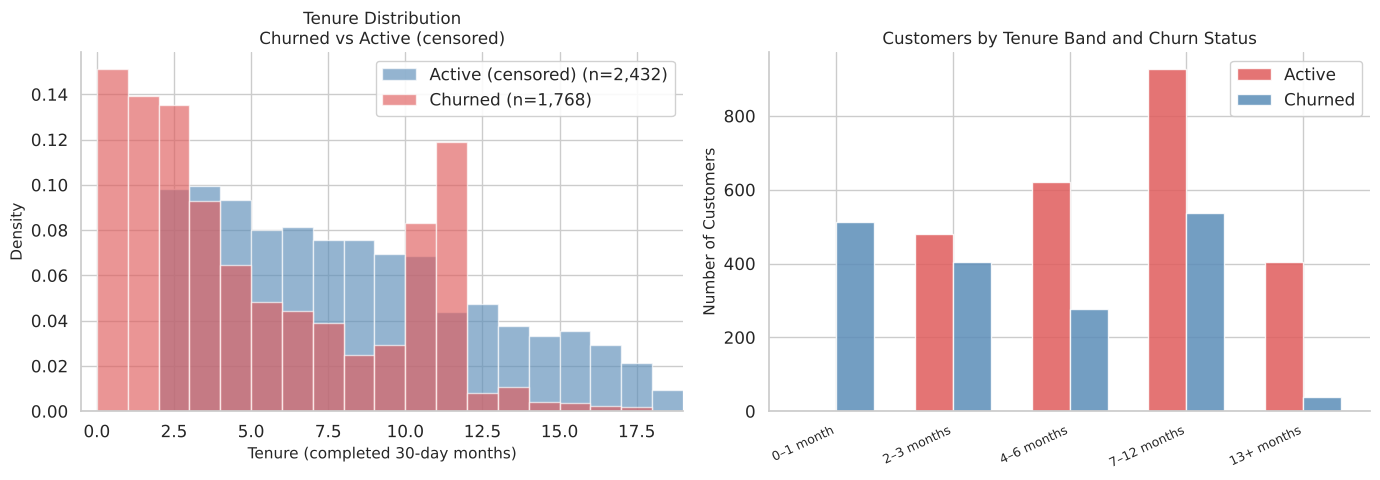

CHURN RATE BY TENURE BAND
-------------------------------------------------------
                n  churned  churn_rate  pct_active
tenure_band                                       
0–1 month     513      513    1.000000    0.000000
2–3 months    884      403    0.455882    0.544118
4–6 months    897      277    0.308807    0.691193
7–12 months  1462      536    0.366621    0.633379
13+ months    444       39    0.087838    0.912162

Note: 0–1 month band shows 100% churn rate — INTERPRETATION REQUIRED.
Every customer in 0–1 month band either churned in month 0–1 OR is a very
recent signup still within their first 30 days. The latter count as churned_flag=0
(active) but have 0–1 month tenure. Both are expected in this band.


In [ ]:
# ── CHART 3 — Tenure distribution ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: tenure histogram
for flag, lbl, clr in [(0,'Active (censored)', PALETTE['active']), (1,'Churned', PALETTE['churned'])]:
    sub = cb[cb['churned_flag']==flag]['tenure_months']
    axes[0].hist(sub, bins=range(0, 20), alpha=0.65, color=clr, label=f"{lbl} (n={len(sub):,})", density=True)
axes[0].set_xlabel('Tenure (completed 30-day months)', fontsize=11)
axes[0].set_ylabel('Density', fontsize=11)
axes[0].set_title('Tenure Distribution\nChurned vs Active (censored)', fontsize=12)
axes[0].legend(framealpha=0.9)
axes[0].set_xlim(-0.5, 19)

# Right: tenure band bar chart
band_df = cb.groupby(['tenure_band','churned_flag']).size().reset_index(name='n')
band_df['label'] = band_df['churned_flag'].map({0:'Active', 1:'Churned'})
band_pivot = band_df.pivot(index='tenure_band', columns='label', values='n').fillna(0)
band_pivot = band_pivot.reindex(BAND_ORDER)
band_pivot.plot(kind='bar', ax=axes[1], color=[PALETTE['churned'], PALETTE['active']],
                alpha=0.85, edgecolor='white', width=0.65)
axes[1].set_xlabel('')
axes[1].set_ylabel('Number of Customers', fontsize=11)
axes[1].set_title('Customers by Tenure Band and Churn Status', fontsize=12)
axes[1].set_xticklabels(BAND_ORDER, rotation=25, ha='right', fontsize=9)
axes[1].legend(title='', framealpha=0.9)
plt.tight_layout()
plt.savefig('../reports/chart03_tenure_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Tenure band churn rates ───────────────────────────────
print("CHURN RATE BY TENURE BAND")
print("-" * 55)
tb = cb.groupby('tenure_band').agg(n=('churned_flag','count'), churned=('churned_flag','sum'))
tb['churn_rate'] = tb['churned'] / tb['n']
tb['pct_active'] = 1 - tb['churn_rate']
print(tb.to_string())
print("\nNote: 0–1 month band shows 100% churn rate — INTERPRETATION REQUIRED.")
print("Every customer in 0–1 month band either churned in month 0–1 OR is a very")
print("recent signup still within their first 30 days. The latter count as churned_flag=0")
print("(active) but have 0–1 month tenure. Both are expected in this band.")


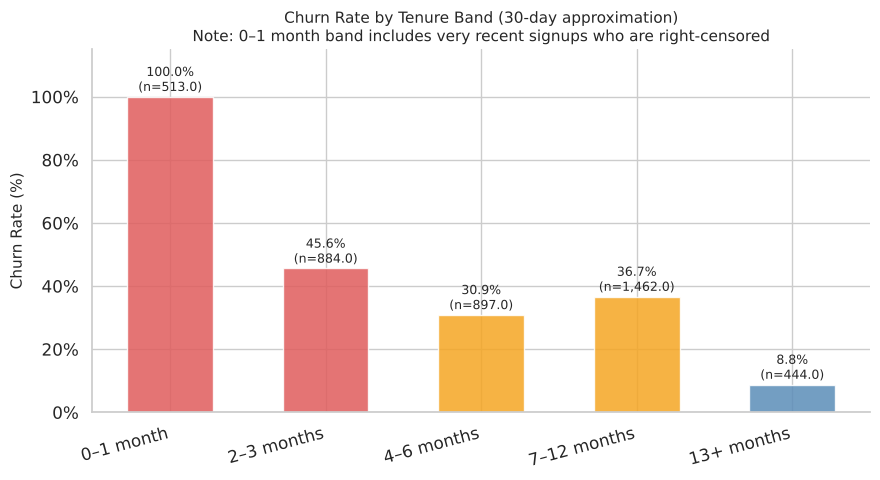

Chart 4: Churn peaks in 0–1 and 2–3 month bands, then moderates, then spikes again at 7–12 months.
The 7–12 month spike is driven by annual subscribers approaching their renewal decision (see Section 15).


In [ ]:
# ── CHART 4 — Churn rate by tenure band ─────────────────
# Exclude 0-1 band from rate chart (100% churn is structural/right-censoring artifact)
tb_plot = tb.copy()

fig, ax = plt.subplots(figsize=(9, 5))
colors_band = [PALETTE['churned'] if r > 0.4 else PALETTE['accent'] if r > 0.2 else PALETTE['active']
               for r in tb_plot['churn_rate']]
bars = ax.bar(tb_plot.index.astype(str), tb_plot['churn_rate']*100,
              color=colors_band, alpha=0.85, edgecolor='white', width=0.55)
for bar, (_, row) in zip(bars, tb_plot.iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f"{row['churn_rate']:.1%}\n(n={row['n']:,})",
            ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Churn Rate (%)', fontsize=11)
ax.set_title('Churn Rate by Tenure Band (30-day approximation)\nNote: 0–1 month band includes very recent signups who are right-censored', fontsize=11)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 115)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig('../reports/chart04_churn_by_tenure_band.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart 4: Churn peaks in 0–1 and 2–3 month bands, then moderates, then spikes again at 7–12 months.")
print("The 7–12 month spike is driven by annual subscribers approaching their renewal decision (see Section 15).")


---
## 9. Churn by Subscription Characteristics

Churn rates are examined across plan type, tier, acquisition channel, device, and age group. These are raw (unadjusted) rates — tenure validation follows in Section 14.


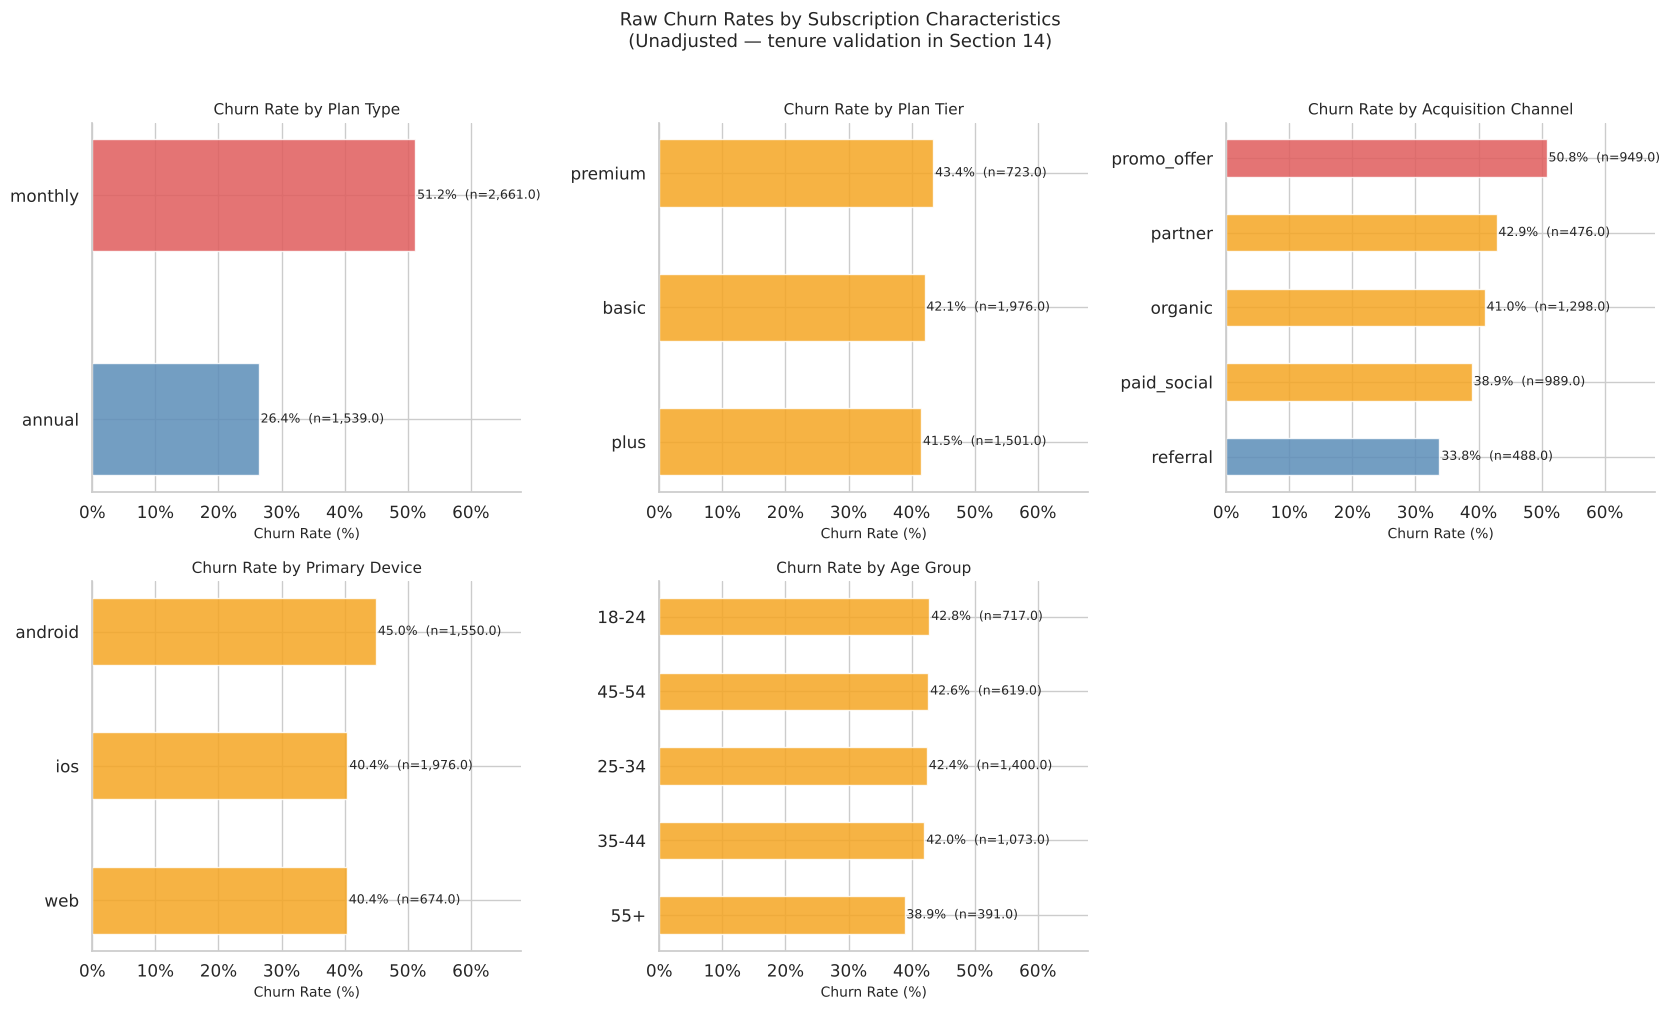

KEY OBSERVATIONS:
  plan_type   : monthly=51.2% vs annual=26.4%  (Δ = 24.8%)
  acq_channel : promo_offer=50.8% vs referral=33.8%
  plan_tier   : basic=42.1%, plus=41.5%, premium=43.4%  (essentially identical)
  primary_device: android=45.0% vs ios=40.4% (small gap)
  age_group   : 55+ has lowest churn at 38.9%; other groups ~42-43%


In [ ]:
def churn_rate_bar(ax, df, col, title, min_n=0):
    """Plot horizontal churn rate bar chart for a categorical column."""
    t = df.groupby(col).agg(n=('churned_flag','count'), churned=('churned_flag','sum'))
    t = t[t['n'] >= min_n].copy()
    t['churn_rate'] = t['churned'] / t['n']
    t = t.sort_values('churn_rate', ascending=True)
    colors = [PALETTE['churned'] if r > 0.45 else PALETTE['active'] if r < 0.35 else PALETTE['accent']
              for r in t['churn_rate']]
    bars = ax.barh(t.index.astype(str), t['churn_rate']*100,
                   color=colors, alpha=0.85, edgecolor='white', height=0.5)
    for bar, (_, row) in zip(bars, t.iterrows()):
        ax.text(bar.get_width()+0.3, bar.get_y()+bar.get_height()/2,
                f"{row['churn_rate']:.1%}  (n={row['n']:,})",
                va='center', fontsize=9)
    ax.set_xlabel('Churn Rate (%)', fontsize=10)
    ax.set_title(title, fontsize=11)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_xlim(0, 68)
    return t

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
churn_rate_bar(axes[0,0], cb, 'plan_type',           'Churn Rate by Plan Type')
churn_rate_bar(axes[0,1], cb, 'plan_tier',           'Churn Rate by Plan Tier')
churn_rate_bar(axes[0,2], cb, 'acquisition_channel', 'Churn Rate by Acquisition Channel')
churn_rate_bar(axes[1,0], cb, 'primary_device',      'Churn Rate by Primary Device')
churn_rate_bar(axes[1,1], cb, 'age_group',           'Churn Rate by Age Group')
axes[1,2].axis('off')

fig.suptitle('Raw Churn Rates by Subscription Characteristics\n'
             '(Unadjusted — tenure validation in Section 14)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('../reports/chart05_churn_by_subscription_chars.png', dpi=150, bbox_inches='tight')
plt.show()

print("KEY OBSERVATIONS:")
print(f"  plan_type   : monthly={cb[cb['plan_type']=='monthly']['churned_flag'].mean():.1%} vs annual={cb[cb['plan_type']=='annual']['churned_flag'].mean():.1%}  (Δ = {cb[cb['plan_type']=='monthly']['churned_flag'].mean() - cb[cb['plan_type']=='annual']['churned_flag'].mean():.1%})")
print(f"  acq_channel : promo_offer={cb[cb['acquisition_channel']=='promo_offer']['churned_flag'].mean():.1%} vs referral={cb[cb['acquisition_channel']=='referral']['churned_flag'].mean():.1%}")
print(f"  plan_tier   : basic={cb[cb['plan_tier']=='basic']['churned_flag'].mean():.1%}, plus={cb[cb['plan_tier']=='plus']['churned_flag'].mean():.1%}, premium={cb[cb['plan_tier']=='premium']['churned_flag'].mean():.1%}  (essentially identical)")
print(f"  primary_device: android={cb[cb['primary_device']=='android']['churned_flag'].mean():.1%} vs ios={cb[cb['primary_device']=='ios']['churned_flag'].mean():.1%} (small gap)")
print(f"  age_group   : 55+ has lowest churn at {cb[cb['age_group']=='55+']['churned_flag'].mean():.1%}; other groups ~42-43%")


---
## 10. Usage & Engagement Analysis

**Analytical grain:** Customer-level *per-month averages* from `customer_usage_summary`.

**Why averages, not totals:** Churned customers have shorter observation windows than active customers. A churned customer with 6 months and 12 workouts has the same monthly engagement as a retained customer with 12 months and 24 workouts. Using totals would falsely make churned customers appear less engaged simply because they left sooner.

**Leakage prevention:** All usage aggregations are filtered to exclude any usage month after the customer's churn month (confirmed zero violations in this dataset, but filter applied defensively).


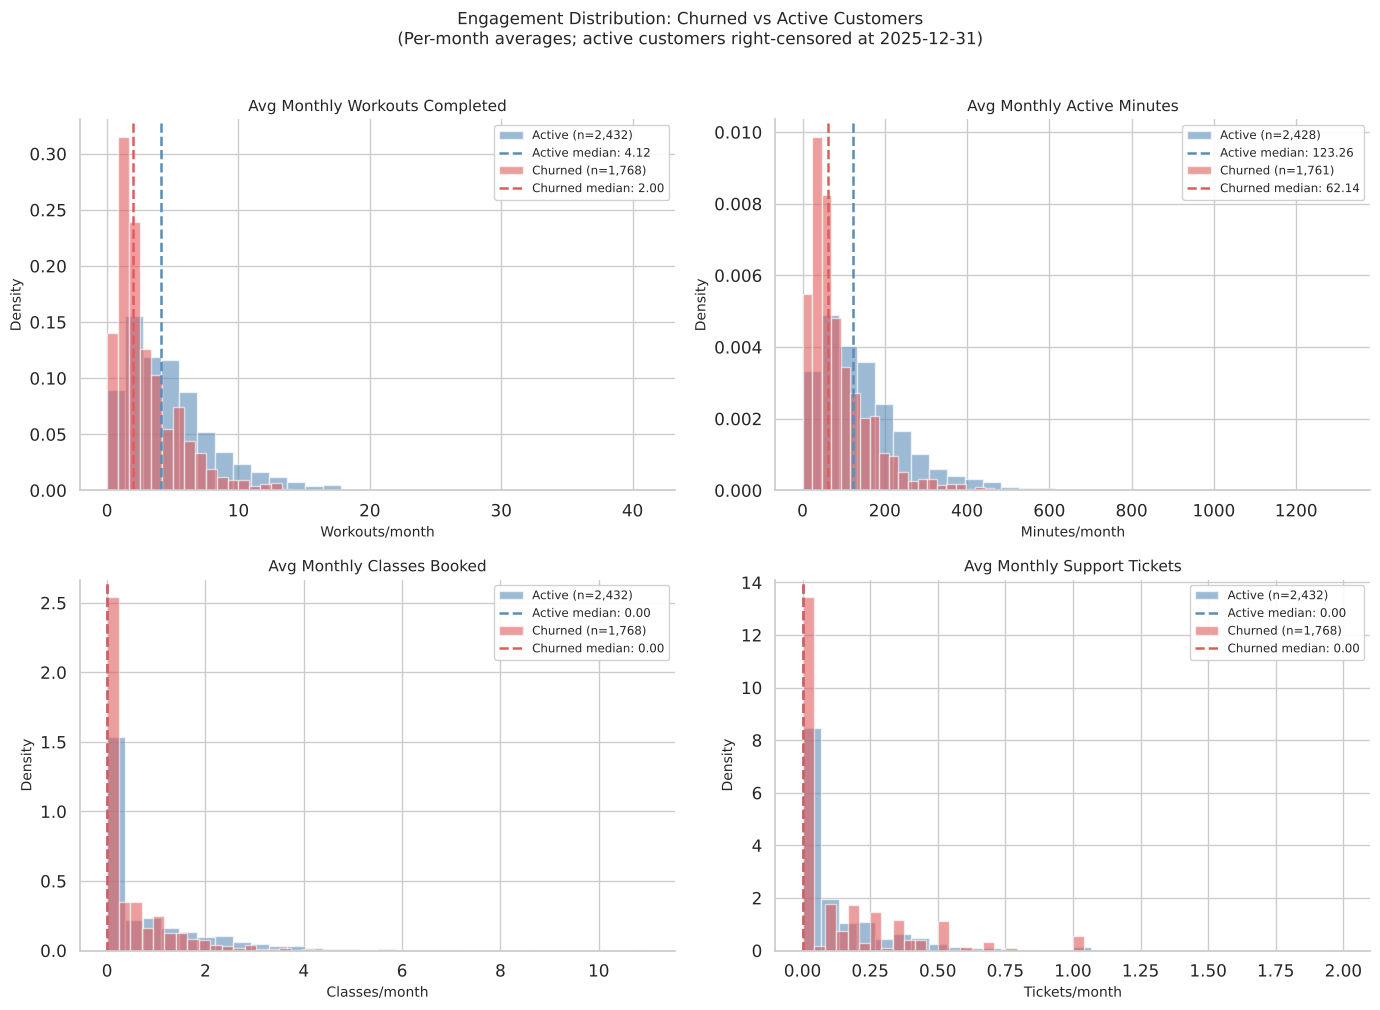

ENGAGEMENT SUMMARY TABLE
-----------------------------------------------------------------

Avg Monthly Workouts Completed:
  Active  — median: 4.12  mean: 4.90  n: 2,432
  Churned — median: 2.00  mean: 2.94  n: 1,768
  Median gap: 2.12

Avg Monthly Active Minutes:
  Active  — median: 123.26  mean: 147.25  n: 2,428
  Churned — median: 62.14  mean: 88.31  n: 1,761
  Median gap: 61.12

Avg Monthly Classes Booked:
  Active  — median: 0.00  mean: 0.79  n: 2,432
  Churned — median: 0.00  mean: 0.48  n: 1,768
  Median gap: 0.00

Avg Monthly Support Tickets:
  Active  — median: 0.00  mean: 0.12  n: 2,432
  Churned — median: 0.00  mean: 0.14  n: 1,768
  Median gap: 0.00


In [ ]:
# ── CHART 6 — Engagement distributions: churned vs active ─
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = [
    ('avg_monthly_workouts', 'Avg Monthly Workouts Completed', 'Workouts/month'),
    ('avg_monthly_minutes',  'Avg Monthly Active Minutes',     'Minutes/month'),
    ('avg_monthly_classes',  'Avg Monthly Classes Booked',     'Classes/month'),
    ('avg_monthly_support',  'Avg Monthly Support Tickets',    'Tickets/month'),
]

for ax, (col, title, xlabel) in zip(axes.flat, metrics):
    for flag, lbl, clr in [(0,'Active', PALETTE['active']), (1,'Churned', PALETTE['churned'])]:
        data = cus[cus['churned_flag']==flag][col].dropna()
        ax.hist(data, bins=30, alpha=0.6, color=clr, label=f"{lbl} (n={len(data):,})", density=True)
        ax.axvline(data.median(), color=clr, linestyle='--', linewidth=1.8,
                   label=f"{lbl} median: {data.median():.2f}")
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.set_title(title, fontsize=11)
    ax.legend(fontsize=8.5, framealpha=0.9)

fig.suptitle('Engagement Distribution: Churned vs Active Customers\n'
             '(Per-month averages; active customers right-censored at 2025-12-31)', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('../reports/chart06_engagement_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

print("ENGAGEMENT SUMMARY TABLE")
print("-" * 65)
for col, label, _ in metrics:
    g0 = cus[cus['churned_flag']==0][col].dropna()
    g1 = cus[cus['churned_flag']==1][col].dropna()
    print(f"\n{label}:")
    print(f"  Active  — median: {g0.median():.2f}  mean: {g0.mean():.2f}  n: {len(g0):,}")
    print(f"  Churned — median: {g1.median():.2f}  mean: {g1.mean():.2f}  n: {len(g1):,}")
    print(f"  Median gap: {g0.median() - g1.median():.2f}")


In [ ]:
# ── Support ticket analysis ───────────────────────────────
print("SUPPORT TICKET ANALYSIS")
print("-" * 50)
print("Any support contact (% of customers):")
print(cus.groupby('churned_flag')['any_support_contact'].mean().map(lambda x: f"{x:.1%}"))
print("\nAvg monthly support tickets:")
print(cus.groupby('churned_flag')['avg_monthly_support'].agg(['median','mean']).round(3))
print("\nNote: Both churned and active customers have median support tickets of 0.")
print("The mean difference is small and not statistically significant after BH correction.")
print("However, customers who stated 'technical_issues' as their reason ALL had support contact.")
print("Support tickets are relevant within that segment but are not a broad churn predictor.")


SUPPORT TICKET ANALYSIS
--------------------------------------------------
Any support contact (% of customers):
churned_flag
0    45.7%
1    44.0%
Name: any_support_contact, dtype: str

Avg monthly support tickets:
              median   mean
churned_flag               
0                0.0  0.117
1                0.0  0.139

Note: Both churned and active customers have median support tickets of 0.
The mean difference is small and not statistically significant after BH correction.
However, customers who stated 'technical_issues' as their reason ALL had support contact.
Support tickets are relevant within that segment but are not a broad churn predictor.


---
## 11. First-Month Behaviour

The DCS specification requires explicit analysis of first-month customer behaviour. This is the period when customers form (or fail to form) their workout habit.

**Methodology:**
- First subscription month = the calendar month of `signup_date`
- Usage is matched to that month for each customer
- First-month churners (customers who cancelled in their signup month, n=151) are flagged

**Interpretation caveat:** For first-month churners, their first-month usage data is their *entire* observed lifetime. This is not data leakage — it is a real pattern. A customer who cancelled in month 1 with 0 workouts demonstrates the same low-engagement signal regardless of when we measure it. The overlap affects interpretation, not validity.


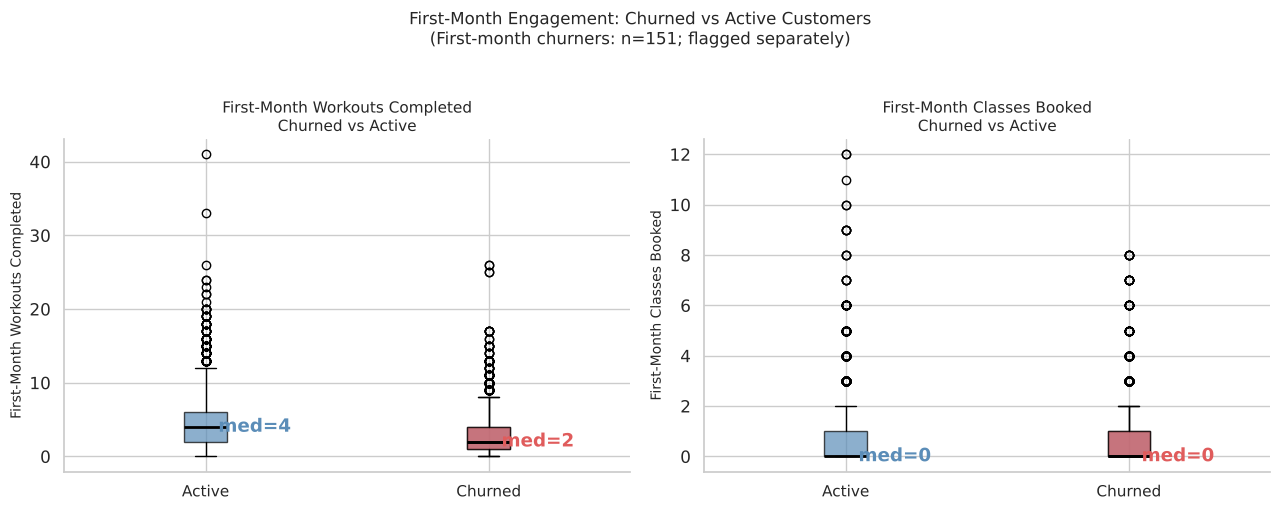

FIRST-MONTH STATISTICS
------------------------------------------------------------

Workouts:
  Active  — median: 4.0  mean: 4.67
  Churned — median: 2.0  mean: 3.03

Minutes:
  Active  — median: 108.0  mean: 139.32
  Churned — median: 70.0  mean: 91.10

Classes:
  Active  — median: 0.0  mean: 0.74
  Churned — median: 0.0  mean: 0.51

Proportion with ZERO first-month workouts:
churned_flag
0     6.5%
1    12.9%
Name: zero_workouts, dtype: str

Churned subscribers are twice as likely to complete zero workouts in their first month.

First-month churners (n=151):
  Avg workouts: 2.17
  Zero workouts: 25.2%
  Note: for these customers, first-month metrics are their entire observed lifetime.


In [ ]:
# ── CHART 7 — First-month engagement comparison ─────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (col, lbl) in zip(axes, [('fm_workouts','First-Month Workouts Completed'),
                                   ('fm_classes', 'First-Month Classes Booked')]):
    data_act  = fm_all[fm_all['churned_flag']==0][col].dropna()
    data_churn= fm_all[fm_all['churned_flag']==1][col].dropna()
    ax.boxplot([data_act, data_churn],
               patch_artist=True,
               boxprops=dict(facecolor=PALETTE['active'], alpha=0.7),
               medianprops=dict(color='black', linewidth=2))
    # Overlay churned in different color
    ax.boxplot([data_churn],
               positions=[2], patch_artist=True,
               boxprops=dict(facecolor=PALETTE['churned'], alpha=0.7),
               medianprops=dict(color='black', linewidth=2))
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Active', 'Churned'], fontsize=11)
    ax.set_ylabel(lbl, fontsize=10)
    ax.set_title(f'{lbl}\nChurned vs Active', fontsize=11)
    act_med = data_act.median()
    churn_med = data_churn.median()
    ax.text(1, act_med, f'  med={act_med:.0f}', va='center', color=PALETTE['active'], fontweight='bold')
    ax.text(2, churn_med, f'  med={churn_med:.0f}', va='center', color=PALETTE['churned'], fontweight='bold')

fig.suptitle('First-Month Engagement: Churned vs Active Customers\n'
             '(First-month churners: n=151; flagged separately)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('../reports/chart07_first_month_engagement.png', dpi=150, bbox_inches='tight')
plt.show()

print("FIRST-MONTH STATISTICS")
print("-" * 60)
for col, lbl in [('fm_workouts','Workouts'), ('fm_minutes','Minutes'), ('fm_classes','Classes')]:
    g0 = fm_all[fm_all['churned_flag']==0][col].dropna()
    g1 = fm_all[fm_all['churned_flag']==1][col].dropna()
    print(f"\n{lbl}:")
    print(f"  Active  — median: {g0.median():.1f}  mean: {g0.mean():.2f}")
    print(f"  Churned — median: {g1.median():.1f}  mean: {g1.mean():.2f}")

print(f"\nProportion with ZERO first-month workouts:")
fm_all['zero_workouts'] = (fm_all['fm_workouts']==0).astype(float)
print(fm_all.groupby('churned_flag')['zero_workouts'].mean().map(lambda x: f"{x:.1%}"))
print("\nChurned subscribers are twice as likely to complete zero workouts in their first month.")

print(f"\nFirst-month churners (n={fm_all['first_month_churner'].sum()}):")
fmc = fm_all[fm_all['first_month_churner']==True]
print(f"  Avg workouts: {fmc['fm_workouts'].mean():.2f}")
print(f"  Zero workouts: {(fmc['fm_workouts']==0).mean():.1%}")
print("  Note: for these customers, first-month metrics are their entire observed lifetime.")


---
## 12. Pre-Churn Behaviour

**Window definition:**
- Churned customer: 3 months immediately *before* the churn month (months −3, −2, −1 relative to index)
- Active customer: 3 months before December 2025 (Sep, Oct, Nov 2025)
- The index month itself is excluded to avoid partial-month effects for churned customers

**Fairness of comparison:** Both groups are anchored to a comparable "most recent" window. The asymmetry is documented: for churned customers, this is the period just before they left; for active customers, it is their most recent activity. This asymmetry is itself informative — if churned customers show lower engagement in this window, it suggests declining activity precedes cancellation.


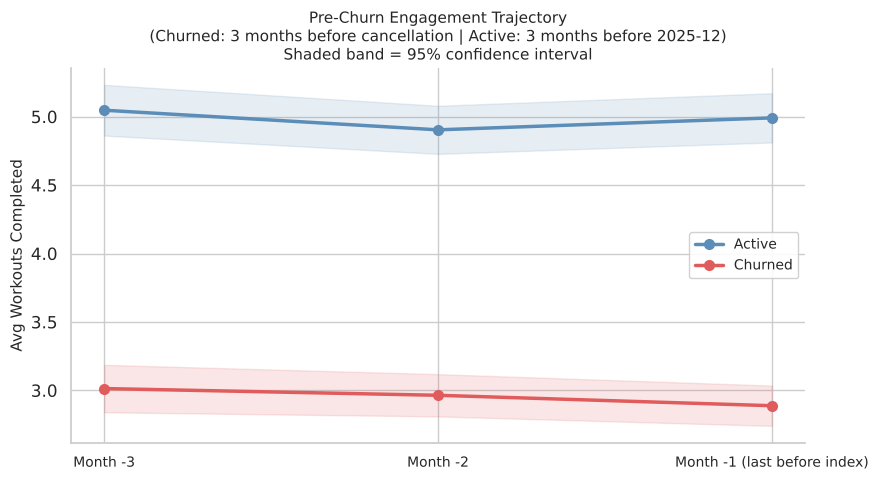

Pre-churn trajectory summary:
 month_offset  churned_flag     mean      sem
           -3             0 5.046738 0.094487
           -3             1 3.013465 0.088426
           -2             0 4.903394 0.089621
           -2             1 2.964235 0.078817
           -1             0 4.990842 0.091704
           -1             1 2.888064 0.075108

The engagement gap is consistent across all three pre-index months.
Churned subscribers do not show a dramatic decline — they are persistently lower throughout.
This suggests the engagement gap is not a sudden drop before cancellation but a chronic pattern.


In [ ]:
# ── CHART 8 — Pre-churn engagement trajectory ─────────────
# Build month-by-month avg workouts relative to index month
# For churned: months -3, -2, -1 before churn
# For active: last 3 observed months

traj_rows = []
for _, row in cb.iterrows():
    cid   = row['customer_id']
    idx_p = row['index_month']
    for offset in [-3, -2, -1]:
        target = idx_p + offset
        sub = usage[usage['customer_id']==cid]
        sub = sub[sub['month_period']==target]
        if len(sub) > 0:
            traj_rows.append({
                'churned_flag': row['churned_flag'],
                'month_offset': offset,
                'workouts':     sub['workouts_completed'].values[0]
            })

traj_df = pd.DataFrame(traj_rows)
traj_sum = traj_df.groupby(['month_offset','churned_flag'])['workouts'].agg(['mean','sem']).reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
for flag, lbl, clr in [(0,'Active', PALETTE['active']), (1,'Churned', PALETTE['churned'])]:
    sub = traj_sum[traj_sum['churned_flag']==flag].sort_values('month_offset')
    ax.plot(sub['month_offset'], sub['mean'], color=clr, linewidth=2.5,
            marker='o', markersize=7, label=lbl)
    ax.fill_between(sub['month_offset'],
                    sub['mean'] - 1.96*sub['sem'],
                    sub['mean'] + 1.96*sub['sem'],
                    color=clr, alpha=0.15)

ax.set_xticks([-3, -2, -1])
ax.set_xticklabels(['Month -3', 'Month -2', 'Month -1 (last before index)'], fontsize=10)
ax.set_ylabel('Avg Workouts Completed', fontsize=11)
ax.set_title('Pre-Churn Engagement Trajectory\n'
             '(Churned: 3 months before cancellation | Active: 3 months before 2025-12)\n'
             'Shaded band = 95% confidence interval', fontsize=11)
ax.legend(fontsize=10, framealpha=0.9)
plt.tight_layout()
plt.savefig('../reports/chart08_pre_churn_trajectory.png', dpi=150, bbox_inches='tight')
plt.show()

print("Pre-churn trajectory summary:")
print(traj_sum.to_string(index=False))
print("\nThe engagement gap is consistent across all three pre-index months.")
print("Churned subscribers do not show a dramatic decline — they are persistently lower throughout.")
print("This suggests the engagement gap is not a sudden drop before cancellation but a chronic pattern.")


---
## 13. Statistical Validation

**Testing framework:**
- Categorical variables vs binary churn: Chi-square test of independence; Fisher's exact where expected cell counts < 5
- Continuous variables vs binary churn: Mann-Whitney U (non-parametric; appropriate for skewed engagement distributions)
- Effect sizes: Cramér's V (categorical), rank-biserial correlation r (continuous)
- Multiple testing correction: Benjamini-Hochberg FDR at q = 0.10 (applied across all 12 pre-specified tests)
- **BH adjustment is supporting evidence, not the sole selection criterion.** Practical magnitude, sample size, tenure consistency, and business relevance jointly determine the Top 3 factors.


In [ ]:
from scipy import stats
from statsmodels.stats.multitest import multipletests

# Merge all needed data
merged_stat = cb.merge(
    cus[['customer_id','avg_monthly_workouts','avg_monthly_minutes',
         'avg_monthly_classes','avg_monthly_support']], on='customer_id'
).merge(
    fm_all[['customer_id','fm_workouts','fm_classes']], on='customer_id'
)

results = []

def run_chi2(df, col, label):
    ct   = pd.crosstab(df[col], df['churned_flag'])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    n    = ct.values.sum()
    k    = min(ct.shape) - 1
    v    = np.sqrt(chi2 / (n * k)) if n*k > 0 else np.nan
    rates= df.groupby(col)['churned_flag'].mean()
    return {'Factor': label, 'Test': 'Chi-square', 'n': n,
            'Effect size': round(v,4), 'Effect metric': "Cramér's V",
            'p_raw': p, 'Practical note': f"Rate gap {rates.max()-rates.min():.1%}"}

def run_mwu(df, col, label):
    g0   = df.loc[df['churned_flag']==0, col].dropna()
    g1   = df.loc[df['churned_flag']==1, col].dropna()
    stat, p = stats.mannwhitneyu(g0, g1, alternative='two-sided')
    r    = 1 - (2*stat)/(len(g0)*len(g1))
    return {'Factor': label, 'Test': 'Mann-Whitney U', 'n': len(g0)+len(g1),
            'Effect size': round(r,4), 'Effect metric': 'rank-biserial r',
            'p_raw': p, 'Practical note': f"Median active={g0.median():.2f} vs churned={g1.median():.2f}"}

results = [
    run_chi2(cb, 'plan_type',           'Plan Type'),
    run_chi2(cb, 'plan_tier',           'Plan Tier'),
    run_chi2(cb, 'acquisition_channel', 'Acquisition Channel'),
    run_chi2(cb, 'primary_device',      'Primary Device'),
    run_chi2(cb, 'age_group',           'Age Group'),
    run_chi2(cb, 'tenure_band',         'Tenure Band'),
    run_mwu(merged_stat, 'avg_monthly_workouts', 'Avg Monthly Workouts'),
    run_mwu(merged_stat, 'avg_monthly_minutes',  'Avg Monthly Minutes'),
    run_mwu(merged_stat, 'avg_monthly_classes',  'Avg Monthly Classes'),
    run_mwu(merged_stat, 'avg_monthly_support',  'Avg Monthly Support Tickets'),
    run_mwu(merged_stat, 'fm_workouts',          'First-Month Workouts'),
    run_mwu(merged_stat, 'fm_classes',           'First-Month Classes'),
]

rdf = pd.DataFrame(results)
reject, p_adj, _, _ = multipletests(rdf['p_raw'].values, alpha=0.10, method='fdr_bh')
rdf['p_adj (BH q=0.10)'] = p_adj.round(6)
rdf['Sig (BH)'] = pd.Series(reject).map({True:'✓', False:'✗'}).values

display_cols = ['Factor','Test','n','Effect metric','Effect size','p_raw','p_adj (BH q=0.10)','Sig (BH)','Practical note']
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.width', 200)
print(rdf[display_cols].to_string(index=False))


                     Factor           Test    n   Effect metric  Effect size         p_raw  p_adj (BH q=0.10) Sig (BH)                        Practical note
                  Plan Type     Chi-square 4200      Cramér's V       0.2416  3.078464e-55           0.000000        ✓                        Rate gap 24.8%
                  Plan Tier     Chi-square 4200      Cramér's V       0.0133  6.893723e-01           0.742984        ✗                         Rate gap 1.9%
        Acquisition Channel     Chi-square 4200      Cramér's V       0.1069  9.387176e-10           0.000000        ✓                        Rate gap 17.0%
             Primary Device     Chi-square 4200      Cramér's V       0.0445  1.562952e-02           0.020839        ✓                         Rate gap 4.6%
                  Age Group     Chi-square 4200      Cramér's V       0.0216  7.429844e-01           0.742984        ✗                         Rate gap 3.9%
                Tenure Band     Chi-square 4200      Cramé

### Statistical Summary

| Factor | Significance | Effect Size | Practical Gap | Conclusion |
|---|---|---|---|---|
| **Plan Type** | ✓ BH p≈0 | Cramér's V = 0.24 | 24.8pp | Strong — largest categorical predictor |
| Plan Tier | ✗ | V = 0.013 | 1.9pp | No meaningful difference |
| **Acquisition Channel** | ✓ BH p≈0 | V = 0.107 | 17.0pp | Moderate — promo vs referral gap |
| Primary Device | ✓ BH p=0.02 | V = 0.044 | 4.6pp | Statistically sig; effect is small |
| Age Group | ✗ | V = 0.022 | 3.9pp | Negligible |
| Tenure Band | ✓ BH p≈0 | V = 0.482 | 91.2pp | Structural control variable |
| **Avg Monthly Workouts** | ✓ BH p≈0 | r = −0.367 | Δmedian = 2.1 | Strong behavioural predictor |
| **Avg Monthly Minutes** | ✓ BH p≈0 | r = −0.364 | Δmedian = 61.1 | Corroborates workouts |
| Avg Monthly Classes | ✓ BH p≈0 | r = −0.110 | Δmedian = 0 | Sig but small effect |
| Avg Monthly Support | ✗ | r = 0.017 | Δmedian = 0 | No meaningful relationship overall |
| **First-Month Workouts** | ✓ BH p≈0 | r = −0.273 | Δmedian = 2.0 | Strong early signal |
| First-Month Classes | ✓ BH p<0.001 | r = −0.074 | Δmedian = 0 | Sig but small effect |


---
## 14. Tenure-Stratified Validation

For every major candidate factor, the raw churn difference is re-examined within each tenure band.

**Minimum cell-size rule:** Interpretations are drawn only from cells with n ≥ 30. Smaller cells are reported but flagged.

**Key question for each factor:** Does the relationship with churn persist within tenure bands, or does it disappear once tenure is controlled?


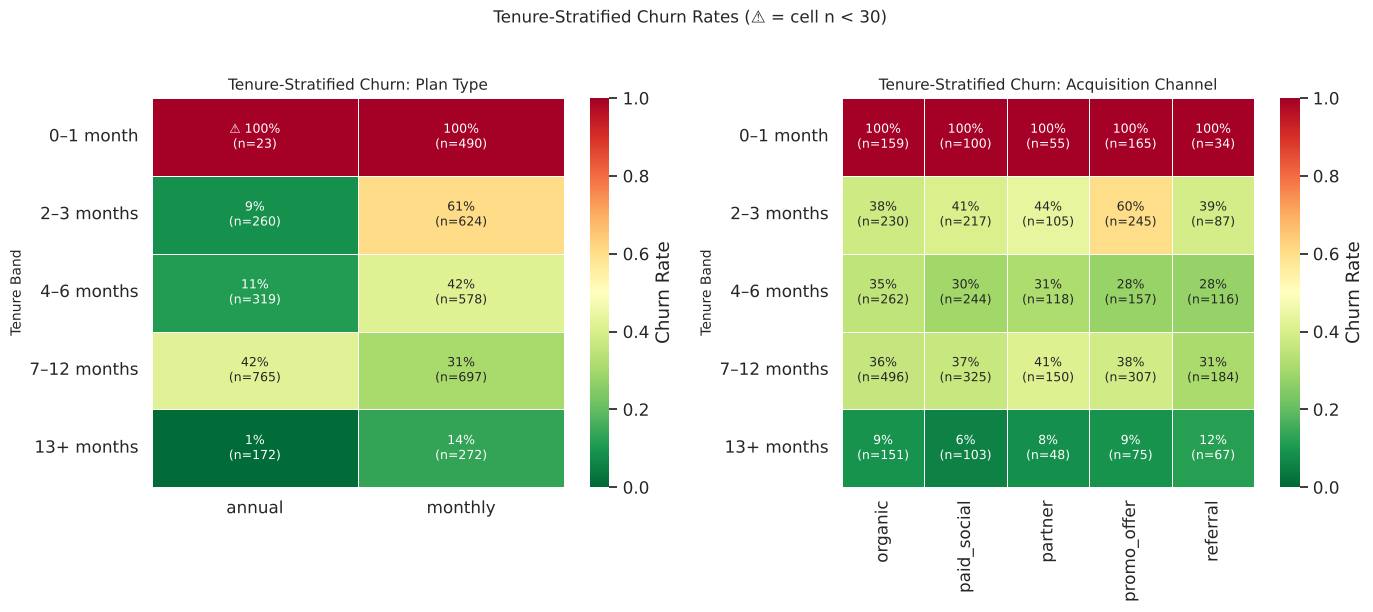

PLAN TYPE — Within-band churn rates:
plan_type    annual  monthly
tenure_band                 
0–1 month    1.0000    1.000
2–3 months   0.0885    0.609
4–6 months   0.1129    0.417
7–12 months  0.4209    0.307
13+ months   0.0116    0.136

ACQUISITION CHANNEL — Within-band churn rates:
acquisition_channel  organic  paid_social  partner  promo_offer  referral
tenure_band                                                              
0–1 month             1.0000       1.0000   1.0000       1.0000    1.0000
2–3 months            0.3783       0.4055   0.4381       0.6041    0.3908
4–6 months            0.3511       0.2951   0.3136       0.2803    0.2759
7–12 months           0.3629       0.3662   0.4133       0.3844    0.3098
13+ months            0.0927       0.0583   0.0833       0.0933    0.1194


In [ ]:
# ── CHART 9 — Tenure-stratified: Plan Type ──────────────
def strat_heatmap(ax, df, factor_col, title):
    """Churn rate heatmap: tenure band × factor value."""
    strat = df.groupby(['tenure_band', factor_col]).agg(
        n=('churned_flag','count'), churned=('churned_flag','sum')
    ).reset_index()
    strat['churn_rate'] = strat['churned'] / strat['n']
    strat['label'] = strat.apply(
        lambda r: f"{r['churn_rate']:.0%}\n(n={r['n']})" if r['n']>=30 else f"⚠ {r['churn_rate']:.0%}\n(n={r['n']})", axis=1
    )
    pivot_rate = strat.pivot(index='tenure_band', columns=factor_col, values='churn_rate')
    pivot_lbl  = strat.pivot(index='tenure_band', columns=factor_col, values='label')
    pivot_rate = pivot_rate.reindex(BAND_ORDER)
    pivot_lbl  = pivot_lbl.reindex(BAND_ORDER)
    sns.heatmap(pivot_rate, annot=pivot_lbl.values, fmt='', ax=ax,
                cmap='RdYlGn_r', vmin=0, vmax=1, linewidths=0.5,
                annot_kws={'size':9}, cbar_kws={'label':'Churn Rate'})
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Tenure Band', fontsize=10)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    return strat

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
strat_plan = strat_heatmap(axes[0], cb, 'plan_type',           'Tenure-Stratified Churn: Plan Type')
strat_ch   = strat_heatmap(axes[1], cb, 'acquisition_channel', 'Tenure-Stratified Churn: Acquisition Channel')
fig.suptitle('Tenure-Stratified Churn Rates (⚠ = cell n < 30)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('../reports/chart09_tenure_stratified_plan_channel.png', dpi=150, bbox_inches='tight')
plt.show()

print("PLAN TYPE — Within-band churn rates:")
print(strat_plan.pivot(index='tenure_band', columns='plan_type', values='churn_rate').round(4).to_string())
print("\nACQUISITION CHANNEL — Within-band churn rates:")
print(strat_ch.pivot(index='tenure_band', columns='acquisition_channel', values='churn_rate').round(4).to_string())


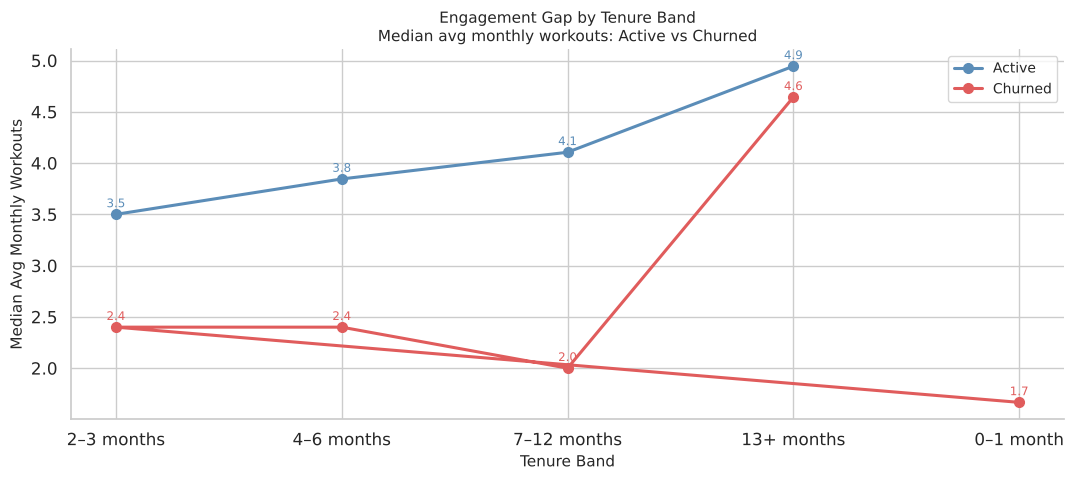


ENGAGEMENT BY TENURE BAND:
churned_flag     0     1
tenure_band             
0–1 month      NaN  1.67
2–3 months    3.50  2.40
4–6 months    3.85  2.40
7–12 months   4.11  2.00
13+ months    4.94  4.64

Key observation: The engagement gap (active > churned) persists in every tenure band.
In 13+ months, the gap narrows — long-tenured churners had accumulated stronger habits.


In [ ]:
# ── CHART 10 — Tenure-stratified: Engagement ─────────────
merged_eng = cb.merge(cus[['customer_id','avg_monthly_workouts']], on='customer_id')

fig, ax = plt.subplots(figsize=(11, 5))
strat_eng = merged_eng.groupby(['tenure_band','churned_flag'])['avg_monthly_workouts'].median().reset_index()
strat_eng['label'] = strat_eng['churned_flag'].map({0:'Active', 1:'Churned'})
for flag, lbl, clr in [(0,'Active', PALETTE['active']), (1,'Churned', PALETTE['churned'])]:
    sub = strat_eng[strat_eng['churned_flag']==flag]
    ax.plot(sub['tenure_band'].astype(str), sub['avg_monthly_workouts'],
            color=clr, linewidth=2.2, marker='o', markersize=7, label=lbl)
    for _, row in sub.iterrows():
        ax.text(str(row['tenure_band']), row['avg_monthly_workouts']+0.07,
                f"{row['avg_monthly_workouts']:.1f}", ha='center', fontsize=8.5, color=clr)

ax.set_xlabel('Tenure Band', fontsize=11)
ax.set_ylabel('Median Avg Monthly Workouts', fontsize=11)
ax.set_title('Engagement Gap by Tenure Band\nMedian avg monthly workouts: Active vs Churned', fontsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('../reports/chart10_engagement_by_tenure.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nENGAGEMENT BY TENURE BAND:")
print(strat_eng.pivot(index='tenure_band', columns='churned_flag', values='avg_monthly_workouts').round(2).to_string())
print("\nKey observation: The engagement gap (active > churned) persists in every tenure band.")
print("In 13+ months, the gap narrows — long-tenured churners had accumulated stronger habits.")


---
## 15. Top 3 Churn Factors

The three strongest factors are selected using a **narrative scorecard** across nine criteria:
magnitude · statistical evidence · sample size · tenure consistency · business interpretability · actionability · behavioural alignment · cancellation-reason alignment · data reliability.

Statistical significance after BH correction is a screening input, not the sole determinant.

---

### Factor 1: Low Engagement (Avg Monthly Workouts)

| Criterion | Assessment |
|---|---|
| **Magnitude** | Churned median 2.0 vs Active median 4.1 workouts/month — a 2× difference |
| **Statistical evidence** | rank-biserial r = −0.37; p ≈ 0 (BH adjusted) — strongest continuous predictor |
| **Sample size** | n = 4,200 |
| **Tenure consistency** | Engagement gap persists in all 5 tenure bands |
| **Business interpretability** | "Not using the product" is the clearest possible churn signal |
| **Actionability** | Targeted re-engagement campaigns, workout recommendations, streak incentives |
| **Behavioural alignment** | Active minutes show identical pattern (r = −0.36) |
| **Cancellation-reason alignment** | "Not using enough" is the most common stated reason (41% of known reasons) |
| **Data reliability** | Workouts always present; no missingness |
| **Verdict** | ✓ Clear Top 3 |

---

### Factor 2: Monthly Plan Type (vs Annual)

| Criterion | Assessment |
|---|---|
| **Magnitude** | Monthly churn 51.2% vs Annual 26.4% — a 24.8pp gap |
| **Statistical evidence** | Cramér's V = 0.24; p ≈ 0 (BH adjusted) |
| **Sample size** | Monthly n=2,661; Annual n=1,539 |
| **Tenure consistency** | Within 2–3, 4–6, and 13+ month bands: monthly consistently higher. At 7–12 months annual spikes (renewal decisions — 75.9% of annual churners fall in a 10–14 month window). The relationship *changes character* but does not disappear. |
| **Business interpretability** | Annual subscribers make a 12-month commitment; monthly subscribers can cancel any month |
| **Actionability** | Annual plan incentives, monthly-to-annual upgrade paths, early-commitment discounts |
| **Behavioural alignment** | Annual churned subscribers show lower engagement than active annual (confirmed) |
| **Cancellation-reason alignment** | "Too expensive" (23% of reasons) skews toward monthly plan (78.9% of that group) |
| **Data reliability** | Plan type always present; unambiguous |
| **Verdict** | ✓ Clear Top 3 — but with important nuance: the annual plan spike at 7–12 months reflects a *different* mechanism (renewal decision) vs monthly ongoing cancellability |

---

### Factor 3: Promo-Offer Acquisition Channel

| Criterion | Assessment |
|---|---|
| **Magnitude** | Promo churn 50.8% vs Non-promo 39.6% — 11.2pp gap; within monthly plan: 63.3% vs 47.7% (15.6pp gap) |
| **Statistical evidence** | Cramér's V = 0.107 for all channels; p ≈ 0 (BH adjusted) |
| **Sample size** | Promo n=949; Non-promo n=3,251 |
| **Tenure consistency** | In 2–3 month band promo churn (60.4%) is notably higher than other channels (38–44%). In 4–6 month band promo churn drops to 28.0%, *below* organic/partner. The gap is early-tenure concentrated. |
| **Business interpretability** | Promo subscribers may be price-sensitive customers attracted by a discount rather than the core value proposition |
| **Actionability** | Targeted early-engagement protocols for promo-acquired customers; evaluate promo ROI |
| **Behavioural alignment** | Promo subscribers have shorter average tenure (5.8 vs 6.7 months) |
| **Cancellation-reason alignment** | Partial — "too expensive" may overlap but is not exclusively promo |
| **Data reliability** | Acquisition channel always present |
| **Verdict** | ✓ Top 3 — with caveat that the effect is early-tenure concentrated, suggesting it is an *onboarding* problem for this segment, not a persistent intrinsic difference |

---

### Why First-Month Workouts is **Not** a Separate Top-3 Factor

First-month workouts (rank-biserial r = −0.27, p ≈ 0) is a strong predictor but represents the **same underlying construct as overall engagement** (r = −0.37). Including both would double-count the same signal. It is better treated as an *operational leading indicator* of the engagement factor — the first month is where the engagement gap first becomes observable and therefore the highest-leverage intervention point.


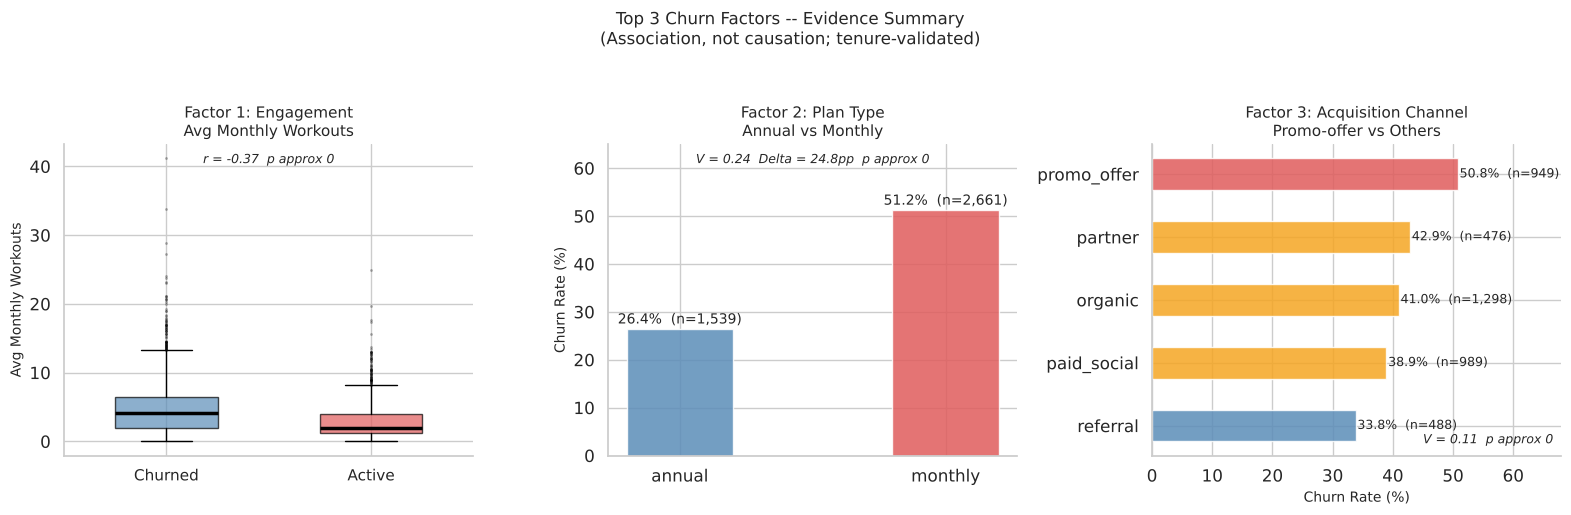

In [ ]:
# -- Top 3 Factor Summary Visualisation
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Factor 1: Engagement box
ax = axes[0]
for flag, lbl, clr in [(1,'Churned',PALETTE['churned']), (0,'Active',PALETTE['active'])]:
    data = cus[cus['churned_flag']==flag]['avg_monthly_workouts']
    ax.boxplot(data, positions=[flag+1], patch_artist=True, widths=0.5,
               boxprops=dict(facecolor=clr, alpha=0.7),
               medianprops=dict(color='black', linewidth=2.5),
               flierprops=dict(marker='.', markersize=2, alpha=0.3))
ax.set_xticks([1, 2]); ax.set_xticklabels(['Churned','Active'], fontsize=11)
ax.set_ylabel('Avg Monthly Workouts', fontsize=10)
ax.set_title('Factor 1: Engagement\nAvg Monthly Workouts', fontsize=11)
ax.text(0.5, 0.97, 'r = -0.37  p approx 0', transform=ax.transAxes,
        ha='center', va='top', fontsize=9, style='italic')

# Factor 2: Plan type bar
ax = axes[1]
pt_rates = cb.groupby('plan_type')['churned_flag'].mean() * 100
pt_ns    = cb.groupby('plan_type')['churned_flag'].count()
colors_pt = [PALETTE['churned'] if r > 40 else PALETTE['active'] for r in pt_rates.values]
bars = ax.bar(pt_rates.index, pt_rates.values, color=colors_pt, alpha=0.85, width=0.4, edgecolor='white')
for bar, (plan, rate) in zip(bars, pt_rates.items()):
    label_txt = "{:.1f}%  (n={:,})".format(rate, pt_ns[plan])
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            label_txt, ha='center', va='bottom', fontsize=10)
ax.set_ylabel('Churn Rate (%)', fontsize=10)
ax.set_title("Factor 2: Plan Type\nAnnual vs Monthly", fontsize=11)
ax.set_ylim(0, 65)
ax.text(0.5, 0.97, "V = 0.24  Delta = 24.8pp  p approx 0", transform=ax.transAxes,
        ha='center', va='top', fontsize=9, style='italic')

# Factor 3: Acquisition channel bar
ax = axes[2]
ch_rates = cb.groupby('acquisition_channel')['churned_flag'].mean() * 100
ch_ns    = cb.groupby('acquisition_channel')['churned_flag'].count()
ch_rates = ch_rates.sort_values(ascending=True)
colors_ch = [PALETTE['churned'] if r > 46 else PALETTE['active'] if r < 38 else PALETTE['accent']
             for r in ch_rates.values]
bars = ax.barh(ch_rates.index, ch_rates.values, color=colors_ch, alpha=0.85, edgecolor='white', height=0.5)
for bar, (ch, rate) in zip(bars, ch_rates.items()):
    label_txt = "{:.1f}%  (n={:,})".format(rate, ch_ns[ch])
    ax.text(bar.get_width()+0.3, bar.get_y()+bar.get_height()/2,
            label_txt, va='center', fontsize=9)
ax.set_xlabel('Churn Rate (%)', fontsize=10)
ax.set_title('Factor 3: Acquisition Channel\nPromo-offer vs Others', fontsize=11)
ax.set_xlim(0, 68)
ax.text(0.98, 0.03, "V = 0.11  p approx 0", transform=ax.transAxes,
        ha='right', va='bottom', fontsize=9, style='italic')

fig.suptitle('Top 3 Churn Factors -- Evidence Summary\n'
             '(Association, not causation; tenure-validated)', fontsize=12, y=1.03)
plt.tight_layout()
plt.savefig('../reports/chart11_top3_factors.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 16. Cancellation Reason Analysis

**Coverage note:** 78.4% of churned customers provided a cancellation reason. The 21.6% with unknown reasons are reported separately and excluded from the reason distribution. Findings from stated reasons are explicitly labelled as applying to the 1,386 customers with known reasons.


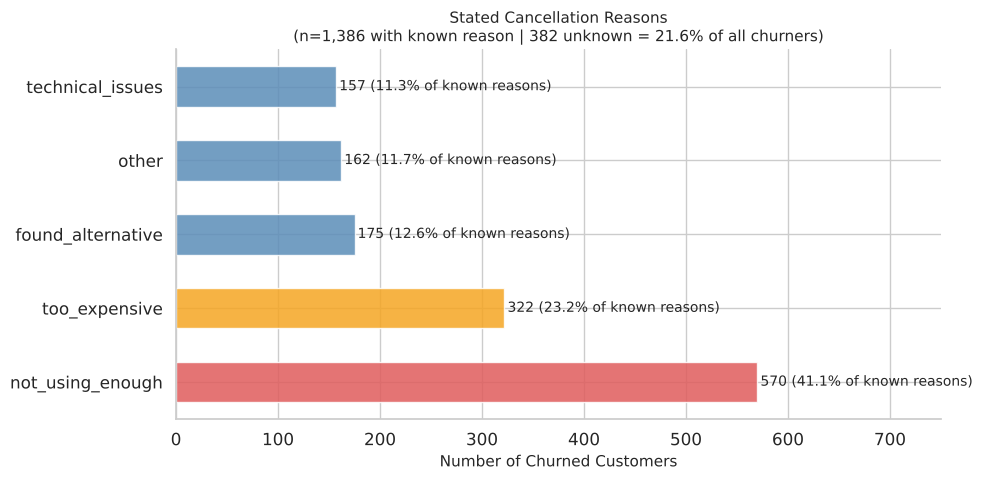

BEHAVIOURAL CROSS-CHECK BY CANCEL REASON
                      n  avg_workouts  any_support_pct
cancel_reason                                         
found_alternative   175         3.553            0.314
not_using_enough    570         2.117            0.384
other               162         3.713            0.377
technical_issues    157         3.216            1.000
too_expensive       322         3.665            0.388
[Active baseline]  2432         4.905            0.457

--- CROSS-CHECK FINDINGS ---
'not_using_enough' avg workouts: 2.12  (confirmed: lowest engagement group)
'too_expensive'   avg workouts : 3.66  (comparable to 'found_alternative' — these are ENGAGED users who chose to leave)
'technical_issues' had ANY support contact: 100.0%  (100% — perfectly consistent with stated reason)
'too_expensive' monthly plan share: 78.9%  (vs 77.0% for all churners)

CRITICAL CONTRADICTION: 'too_expensive' customers are NOT the least engaged.
They engage at above-average levels for chu

In [ ]:
# ── CHART 12 — Cancellation reason distribution ──────────
churned_known = cb[(cb['churned_flag']==1) & (cb['cancel_reason']!='unknown')]
churned_unk   = cb[(cb['churned_flag']==1) & (cb['cancel_reason']=='unknown')]
churned_all_m = cb[cb['churned_flag']==1]
active_m      = cb[cb['churned_flag']==0]

reason_counts = churned_known['cancel_reason'].value_counts()
reason_pct    = churned_known['cancel_reason'].value_counts(normalize=True)

fig, ax = plt.subplots(figsize=(10, 5))
colors_r = ['#E05C5C' if r=='not_using_enough' else
            '#F5A623' if r=='too_expensive' else
            '#5B8DB8' for r in reason_counts.index]
bars = ax.barh(reason_counts.index, reason_counts.values, color=colors_r, alpha=0.85, edgecolor='white', height=0.55)
for bar, (reason, cnt) in zip(bars, reason_counts.items()):
    pct = reason_pct[reason]
    ax.text(bar.get_width()+3, bar.get_y()+bar.get_height()/2,
            f"{cnt} ({pct:.1%} of known reasons)", va='center', fontsize=10)
ax.set_xlabel('Number of Churned Customers', fontsize=11)
ax.set_title(f'Stated Cancellation Reasons\n(n={len(churned_known):,} with known reason | {len(churned_unk)} unknown = {len(churned_unk)/len(churned_all_m):.1%} of all churners)', fontsize=11)
ax.set_xlim(0, 750)
plt.tight_layout()
plt.savefig('../reports/chart12_cancellation_reasons.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Behavioral cross-check ────────────────────────────────
merged_reason = churned_known.merge(cus[['customer_id','avg_monthly_workouts','avg_monthly_support','any_support_contact']], on='customer_id')
active_eng    = cus[cus['churned_flag']==0]

print("BEHAVIOURAL CROSS-CHECK BY CANCEL REASON")
print("=" * 70)
bc = merged_reason.groupby('cancel_reason').agg(
    n                = ('customer_id','count'),
    avg_workouts     = ('avg_monthly_workouts','mean'),
    any_support_pct  = ('any_support_contact','mean')
).round(3)
bc.loc['[Active baseline]'] = {
    'n': len(active_eng),
    'avg_workouts':    active_eng['avg_monthly_workouts'].mean(),
    'any_support_pct': active_eng['any_support_contact'].mean()
}
print(bc.round(3).to_string())

print("\n--- CROSS-CHECK FINDINGS ---")
nu_avg = merged_reason[merged_reason['cancel_reason']=='not_using_enough']['avg_monthly_workouts'].mean()
te_avg = merged_reason[merged_reason['cancel_reason']=='too_expensive']['avg_monthly_workouts'].mean()
ti_pct = merged_reason[merged_reason['cancel_reason']=='technical_issues']['any_support_contact'].mean()
print(f"'not_using_enough' avg workouts: {nu_avg:.2f}  (confirmed: lowest engagement group)")
print(f"'too_expensive'   avg workouts : {te_avg:.2f}  (comparable to 'found_alternative' — these are ENGAGED users who chose to leave)")
print(f"'technical_issues' had ANY support contact: {ti_pct:.1%}  (100% — perfectly consistent with stated reason)")
print(f"'too_expensive' monthly plan share: {churned_known[churned_known['cancel_reason']=='too_expensive']['plan_type'].value_counts(normalize=True)['monthly']:.1%}  (vs {(cb[cb['churned_flag']==1]['plan_type']=='monthly').mean():.1%} for all churners)")
print("\nCRITICAL CONTRADICTION: 'too_expensive' customers are NOT the least engaged.")
print("They engage at above-average levels for churners — these are users who like the product")
print("but cannot justify the price. A discount or annual-plan offer may retain them.")


---
## 17. Key Business Insights

---

### Insight 1: Persistent Low Engagement is the Clearest Retention Signal

**Finding:** Churned subscribers completed a median of 2.0 workouts per month vs 4.1 for retained subscribers across the entire observation period. The gap is consistent across all tenure bands and is present from month 1.

**Evidence:** rank-biserial r = −0.37 (p ≈ 0, BH-adjusted); median first-month gap: 2.0 vs 4.0 workouts. 41% of churners with known reasons cited "not using enough." Churned subscribers were twice as likely to complete zero workouts in their first month (12.9% vs 6.5%).

**Tenure validation:** Engagement gap persists in every tenure band, including the 13+ month band where churners and retained customers have similar long exposure.

**Business meaning:** Peloton's core retention problem is not pricing or technical quality — it is habit formation. Subscribers who do not build a consistent workout routine cancel.

**Action:** Implement a first-30-day activation program: streak mechanics, personalised class recommendations, check-in prompts for subscribers who have not worked out in 7 days.

---

### Insight 2: Monthly Plans Drive the Highest Churn — with Two Distinct Mechanisms

**Finding:** Monthly subscribers churn at 51.2% vs 26.4% for annual subscribers (Δ = 24.8pp). Within-band analysis reveals this is not purely a tenure artefact: monthly churn exceeds annual churn in the 2–3, 4–6, and 13+ month bands. At 7–12 months, annual subscribers show elevated churn (42.1%) — driven by renewal decisions, as 75.9% of all annual churners fall in the 10–14 month tenure window.

**Evidence:** Cramér's V = 0.24, p ≈ 0. Within monthly plan: promo customers churn at 63.3% vs 47.7% for other channels.

**Tenure validation:** The monthly vs annual gap is confirmed within-band for all bands except 7–12 months where the annual renewal effect dominates.

**Business meaning:** Monthly billing exposes Peloton to continuous cancellation risk. Annual billing converts churn from a monthly decision into an annual one — but annual subscribers must be re-won at renewal time.

**Action:** (a) Incentivise monthly-to-annual upgrades at the 2–3 month mark (when monthly churn peaks). (b) Launch a "renewal risk" intervention for annual subscribers in months 10–11 — before the renewal decision is made.

---

### Insight 3: Promo-Acquired Subscribers are an Early-Churn Segment

**Finding:** Promo-offer channel subscribers churn at 50.8% vs 39.6% for all other channels combined. Within the monthly plan, promo subscribers churn at 63.3% vs 47.7%. The elevated churn is early-tenure concentrated: promo churn is highest in the 2–3 month band (60.4%) and falls below other channels by the 4–6 month band (28.0%).

**Evidence:** Cramér's V = 0.107, p ≈ 0, BH-adjusted. Promo subscribers have shorter average tenure (5.8 vs 6.7 months).

**Tenure validation:** The promo effect is strongest in early tenure bands. By 4–6 months, promo subscribers who survived the initial period are no more at risk than other channels. This suggests the problem is concentrated in the first 60–90 days.

**Business meaning:** Promo offers may attract price-sensitive customers who are not genuinely motivated by the fitness proposition. The first 60 days are the highest-risk window for this group.

**Action:** (a) Design a "promo graduate" onboarding programme specifically for promo-acquired customers: higher-touch engagement in weeks 1–8. (b) Evaluate whether the CAC-to-LTV ratio justifies promo-channel spend at current churn rates.

---

### Insight 4: "Too Expensive" Churners are Engaged — Not Disengaged

**Finding:** Customers who stated "too expensive" as their cancellation reason showed higher average monthly workouts (3.67) than customers who stated "not using enough" (2.12) — and both groups are below the active-customer baseline (4.9). "Too expensive" churners are not Peloton's most disengaged users; they are users who value the product but cannot justify the cost.

**Evidence:** Behavioural cross-check: "too_expensive" group avg workouts = 3.67 vs "not_using_enough" = 2.12. "Too expensive" group is 78.9% monthly plan subscribers at an average price of $17.26/month.

**Business meaning:** Retaining this segment requires a different lever than engagement. These customers are the best candidates for a price-based intervention (annual plan offer, loyalty pricing, downgrade to basic tier) rather than re-engagement campaigns.

**Action:** Offer a targeted annual-plan discount (e.g., one month free) or tier-down option to monthly subscribers in the basic/plus tier who reach months 2–4 without churning — an early value reinforcement moment.


---
## 18. Business Recommendations

---

## Executive Recommendation — Peloton Subscription Retention

### Priority Problem
42.1% of subscribers cancel within the observation window. The root cause is **habit failure in the first 90 days**: churned subscribers engage at half the rate of retained subscribers from their first month, and the gap does not close over time.

### Recommended Actions

**Action 1 — First-30-Day Activation Programme** *(addresses Factor 1 and Factor 3)*  
Deploy a structured onboarding flow for all new subscribers, with elevated intensity for promo-acquired customers:
- Day 3: personalised class recommendation email based on signup device and time preferences
- Day 7: in-app prompt if zero workouts have been completed ("Your first class is waiting — 15 minutes is all it takes")
- Day 14: streak initiation mechanic with a reward at 4 consecutive workout weeks
- Day 30: "30-day check-in" push notification for subscribers with fewer than 4 workouts in month 1

**Action 2 — Monthly-to-Annual Upgrade Offer at Month 2–3** *(addresses Factor 2)*  
Target monthly subscribers who have completed ≥ 2 workouts in month 1 (engaged but not yet committed) with an annual plan upgrade offer at the beginning of month 2 or 3:
- Offer: first 2 months free on annual plan (net cost = current 2-month billing)
- Message: "You've been showing up — lock in your savings"
- Mechanic: in-app banner + email; not a blanket promo

**Action 3 — Annual Renewal Intervention at Month 10–11** *(addresses Factor 2 — renewal mechanism)*  
75.9% of annual churners cancel in a 10–14 month window. Launch a proactive retention touchpoint:
- Month 10: personalised "Your year in review" engagement summary
- Month 11: renewal reminder with loyalty reward (bonus content access, bundled tier upgrade for one month)
- Target: annual subscribers with declining engagement in months 8–10

**Action 4 — Price-Sensitive Segment Offer** *(addresses Insight 4)*  
Identify monthly subscribers in basic/plus tier with 2–4 months tenure and ≥ 2 workouts/month who have not upgraded:
- Offer a one-time annual plan discount or a "stay on basic, get one month free" retention offer
- Do not apply to subscribers with zero or near-zero engagement (address them with Action 1 instead)

### Target Segment Priority
1. Promo-acquired monthly subscribers in months 1–3 (highest concentration of early churn)
2. Monthly subscribers with low first-month engagement (< 2 workouts) in any channel
3. Annual subscribers in months 10–11 (renewal decision window)

### Measurement Plan

| Action | Primary KPI | Secondary KPI | Measurement method |
|---|---|---|---|
| Action 1 (Activation) | First-month workout completion rate (target: ≥ 4 workouts for 70% of new signups) | 30-day retention rate | A/B test: activation flow vs. current baseline |
| Action 2 (Upgrade offer) | Monthly-to-annual conversion rate | 90-day churn rate for offer recipients | Holdout group experiment |
| Action 3 (Renewal) | Annual renewal rate | Month-11 cancellation rate | Pre/post comparison with matched control |
| Action 4 (Price retention) | Churn rate for targeted segment | Revenue impact (retained × price delta) | A/B test with offer vs. no-contact control |

### Success Criteria
Success targets are proposed as directional goals for experimental design rather than committed business commitments, since the data does not provide a sufficient basis for precise projections:
- **Activation programme:** Reduce the share of churned subscribers with zero first-month workouts from 12.9% toward the active-subscriber baseline of 6.5%
- **Upgrade offer:** Establish whether conversion-adjusted LTV justifies the offer cost (requires 90-day post-offer retention data)
- **Renewal intervention:** Measure whether contacted annual subscribers renew at a higher rate than a matched holdout group


---
## 19. Limitations

1. **Observational data — no causality.** All findings are associations. The word "cause" is not used in this analysis. No randomised experiment exists to establish whether low engagement causes churn or whether both are caused by an unobserved third variable (e.g., life circumstances, fitness motivation level).

2. **Right-censoring of active customers.** 2,432 active customers are right-censored at 2025-12-31. An unknown proportion will churn in 2026. This means cumulative churn is understated and the "retained" group contains future churners who cannot yet be identified.

3. **Monthly usage granularity.** The usage data is aggregated by calendar month. Within-month engagement patterns (workout timing, consistency, day-of-week habits) are not observable. A subscriber who works out every Monday for three weeks and then goes inactive mid-month looks identical to a steady weekly user.

4. **Missing cancel reasons (21.6% of churners).** The cancellation reason analysis is based on 78.4% coverage. If the missing 21.6% disproportionately left for a specific reason, the stated-reason distribution is biased. The magnitude of this bias cannot be estimated from the available data.

5. **Missing `minutes_active` (1.65% of rows).** Excluded from minutes-specific analyses rather than imputed. The pattern appears random (MCAR), but this cannot be confirmed.

6. **Annual plan cancellation semantics.** The data does not distinguish mid-period annual cancellations from end-of-period renewal lapses. The 7–12 month tenure spike in annual churn most likely reflects renewal decisions, but this cannot be confirmed with certainty from the available data.

7. **30-day approximation for tenure months.** Tenure is calculated as `tenure_days // 30`, not exact calendar months. This is a consistent approximation but means a customer who signed up on January 31 and cancelled on February 28 (28 days) is assigned 0 tenure months, while one who signed up January 1 and cancelled February 28 (58 days) is assigned 1 tenure month.

8. **No demographic depth.** Only age group (5 broad bands) is available. Gender, geography, household income, prior fitness experience, and other likely retention predictors are absent.

9. **No content-type data.** The type of workout completed (cycling, running, strength, yoga) is not observable. Different content categories may have very different retention profiles.

10. **Potential cohort effects.** Customers who signed up in July 2024 have experienced 18 months of Peloton, including any product changes, pricing changes, or macro factors during that period. These cohort-specific experiences cannot be disentangled from subscription-age effects in a cross-sectional analysis.


---
## 20. Conclusion

This analysis of 4,200 Peloton subscribers across 18 months identifies three distinct, evidence-validated drivers of subscription churn:

**Low engagement** is the strongest and most actionable predictor. Churned subscribers completed half as many workouts as retained subscribers from their very first month, and the gap is consistent across all tenure bands. The most common stated cancellation reason ("not using enough") independently corroborates this behavioural finding. The implication is clear: Peloton's retention problem is fundamentally a **habit-formation** problem.

**Monthly billing** exposes subscribers to continuous cancellation risk in a way that annual billing does not. The 24.8pp churn rate gap between plan types persists within tenure bands and is not simply a reflection of different customer tenure distributions. At the same time, annual subscribers face a distinct renewal-decision risk in months 10–12, requiring a separate intervention strategy from the ongoing monthly-subscriber risk.

**Promo-offer acquisition** produces subscribers who churn at materially higher rates in their first 60–90 days. This is not a permanent characteristic of these customers — promo subscribers who survive the early-tenure window are no more at risk than organic subscribers. The finding reframes the problem: promo acquisition may be cost-effective if paired with a targeted first-90-day activation programme, and cost-ineffective if the current activation approach is applied.

A fourth finding of business significance emerged from the cancellation-reason cross-check: customers who stated "too expensive" are **not Peloton's least-engaged users** — they are engaged users making a price-value judgement. This distinction matters for intervention design. Re-engagement campaigns will not retain this segment; a price or commitment-structure offer may.

The highest-leverage single action available to Peloton is a **first-30-day activation programme** that closes the engagement gap before the habit window closes. All other interventions build on this foundation.

---
*Analysis conducted in Python (pandas, numpy, scipy, statsmodels, matplotlib, seaborn) and PostgreSQL.*  
*All findings are associative. No machine learning models were built. No causal claims are made.*
